<a href="https://colab.research.google.com/github/lmauricio5646-code/projects/blob/main/Project_Lorelle_Mauricio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **STAT 200 Project**

#### **Lorelle Mauricio**


---

<br>

For your project, you must analyze data from the [COPDGene study](http://www.copdgene.org/) using the concepts covered in this course. Please follow the directions below carefully:

- <font color=red>Tasks</font> indicated in red must be completed to receive credit
- Include all code for your work
- Comment all code using the `#`. This is a must!
- Include markdown cells with written answers explaining your work when prompted
- **NOTE: Your completed project must be submitted to Canvas as a .ipynb file by the assigned due date**



<br>

---

<br>






## Data

Data for the project is available from three separate data sources.
  * [demographics data](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_demographics.csv)
  * [medical image data](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_imaging.json)
  * [spirometry data](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_spirometry.html)
  
A data dictionary describing the meaning of each of the variables in the dataset is available [here](https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_dictionary.csv).

In [1]:
# install packages
install.packages("dslabs")
install.packages("readxl")   # imports excel spreadsheets
install.packages("writexl")  # exports excel spreadsheets
install.packages("jsonlite")
# load rvest library (already installed in colab!)
library(rvest)
library(dslabs)
library(readxl)
library(writexl)
library(jsonlite)
library(ggplot2)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



<br>

---

<br>






## Introduction

Chronic obstructive pulmonary disease (COPD) affects over 16 million Americans and is the fourth leading cause of death in the United States behind heart disease, cancer, and accidental death. While COPD can result from various toxic inhalations or asthma, it is most commonly associated with cigarette smoking.

<br>

COPD severity is typically measured by a device called a spirometer. Patients forcefully exhale into the device and the volume of air exhaled is used as a measure for the severity of disease (less air exhaled $\Rightarrow$ worse disease). Data collected by the COPDGene research group includes spirometry data on thousands of research participants.

<br>

Spirometry measures in the dataset:
* The forced expiratory volume (FEV1) is the volume of air exhaled in 1 second
* The forced vital capacity (FVC) is the total volume of air exhaled after a full breath
* FEV1_FVC_ratio is the ratio between FEV1 and FVC (smaller $\Rightarrow$ worse disease)
* FEV1_phase2 is the FEV1 of research participants 5 years later

<br>

You overall task in this project is to analyze the relationship between FEV1 at follow-up (FEV1_phase2) and other variables in the dataset. The project has been organized into a series of tasks to assist you with your analysis organization.

<br>

---

<br>






####<font color=red>Organized</font>
* Answers should be organized in the following format for organization and readability

<br>

```
# 1.
This will be the code block to answer the first part of a task
```

1. This will be the text answer/explanation (if prompted) for the first task

```
# 2.
This will be the code block to answer the second part of a task in a separate code cell
```

2. This will be the text answer/explanation (if prompted) for the second task

<br>

Continue this format for the remaining subtasks


<br>

<br>

---






## Data Wrangling

####<font color=red>Task 1</font>

Using code covered in the course,

1. Load the COPDGene demographics dataset.

2. Load the COPDGene medical image dataset as a data frame. You must process the data to ensure the data is stored as a data frame.

3. Load the COPDGene spirometry dataset as a data frame. You must process the data to ensure the data is stored as a data frame.

In [2]:
#1. load csv
demographics <- read.csv("https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_demographics.csv", header = TRUE)
head(demographics)

,sid,visit_year,visit_date,visit_age,gender,race,smoking_status,height_cm,weight_kg,blood_pressure_systolic,blood_pressure_diastolic,heart_rate,hours_on_oxygen,bmi,smoke_start_age,cigs_per_day_avg,duration_smoking,respiratory
,<chr>,<int>,<chr>,<dbl>,<int>,<int>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<int>,<int>,<dbl>,<chr>
1,10005Q,2008,1/15/2008,54.5,2,1,2,159.9,73.0,130,80,87,0,28.55,14,20,40.5,
2,10055F,2008,3/15/2008,69.0,1,2,1,178.0,90.7,168,100,55,0,28.63,18,20,20.0,hay fever
3,10056H,2008,2/15/2008,48.7,2,1,1,153.7,86.2,100,53,98,24,36.49,12,40,36.0,asthma|bronchitis attacks|chronic bronchitis|pneumonia|emphysema|copd|sleep apnea
4,10060Y,2008,5/15/2008,72.8,1,1,1,177.0,89.6,147,71,87,24,28.60,17,30,54.0,asthma|bronchitis attacks|chronic bronchitis|emphysema|copd
5,10068O,2008,3/15/2008,76.2,2,1,1,155.0,55.0,134,78,92,0,22.89,18,20,52.0,hay fever|bronchitis attacks|chronic bronchitis|pneumonia|emphysema|copd
6,10072F,2008,3/15/2008,70.0,2,1,1,165.1,76.1,92,58,77,12,27.92,16,40,48.0,pneumonia|emphysema|copd


In [3]:
#2. load json
imaging <- fromJSON("https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_imaging.json")
class(imaging)
head(imaging)

[1] "data.frame"

,sid,lung_volume_inspiratory,emphysema_percentage,lung_volume_expiratory,gas_trapping_percentage,mean_density_inspiratory,mean_density_expiratory
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,24838L,4.1956,1.3740,2.2976,10.5587,-829.631,-684.559
2,14901M,5.7800,3.7793,2.9900,11.6639,-836.006,-674.285
3,11357A,5.4958,4.7153,2.7493,16.9214,-855.705,-727.824
4,20152J,4.9409,8.4237,3.2121,39.4071,-850.767,-777.023
5,21437E,4.6451,0.0600,2.9805,2.6216,-762.127,-656.432
6,15807Z,5.6987,2.1956,3.0119,12.5120,-844.875,-710.280


In [4]:
#3. load html
html <- read_html("https://raw.githubusercontent.com/khasenst/datasets_teaching/refs/heads/main/copd_data_spirometry.html")
spiro_table <- html_table(html)
spiro <- as.data.frame(spiro_table)
head(spiro)

,sid,fev1_fvc_ratio,fev1,fvc,fev1_phase2
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,22035P,0.62,3.672,5.954,3.484
2,25109H,0.81,1.968,2.432,2.049
3,10127E,0.83,2.319,2.788,2.133
4,15450K,0.51,2.398,4.745,1.424
5,13689J,0.75,3.938,5.273,3.571
6,15749L,0.81,2.784,3.446,2.309


<br>

<br>


---






####<font color=red>Task 2</font>

Using code covered in the course,

1. Merge the demographics, medical imaging, and spirometry datasets by the anonymized ID into a single dataset. Be sure to keep all rows from all datasets.

  Hint: You should have 2,620 observations after the merge.

In [5]:
#1. merge into one data set called "final_merged"
merged1 <- merge(demographics, imaging, by = "sid", all = TRUE)
final_merged <- merge(merged1, spiro, by = "sid", all = TRUE)
#show new and merged data frame; 2620 obs. with 28 vars.
str(final_merged)

'data.frame':	2620 obs. of  28 variables:
 $ sid                     : chr  "10005Q" "10055F" "10056H" "10060Y" ...
 $ visit_year              : int  2008 2008 2008 2008 2008 2008 2008 2008 2008 2008 ...
 $ visit_date              : chr  "1/15/2008" "3/15/2008" "2/15/2008" "5/15/2008" ...
 $ visit_age               : num  54.5 69 48.7 72.8 76.2 70 61.8 69.6 47.8 71.5 ...
 $ gender                  : int  2 1 2 1 2 2 1 2 1 1 ...
 $ race                    : int  1 2 1 1 1 1 1 1 1 1 ...
 $ smoking_status          : int  2 1 1 1 1 1 1 1 2 1 ...
 $ height_cm               : num  160 178 154 177 155 ...
 $ weight_kg               : num  73 90.7 86.2 89.6 55 ...
 $ blood_pressure_systolic : int  130 168 100 147 134 92 108 144 139 140 ...
 $ blood_pressure_diastolic: int  80 100 53 71 78 58 78 90 90 75 ...
 $ heart_rate              : int  87 55 98 87 92 77 72 110 87 73 ...
 $ hours_on_oxygen         : int  0 0 24 24 0 12 0 0 0 24 ...
 $ bmi                     : num  28.6 28.6 36.5 28.6 22.9

<br>

<br>

<br>

---

<br>






####<font color=red>Task 3</font>

Using code covered in the course,

1. Convert the variables `gender`, `race`, and `smoking_status` to factors

2. Reassign the levels appropriately. Hint: See data dictionary.

In [6]:
#gender variable factor: 1 = Male; 2 = Female
final_merged$gender <- factor(final_merged$gender,
                              levels = c(1, 2),
                              labels = c("Male", "Female"))
#race variable as a factor: 1 = White; 2 = Black; 3 = Asian; 4 = Other
final_merged$race <- factor(final_merged$race,
                            levels = c(1, 2),
                            labels = c("White", "Black"))
#smoking_status variable as a factor: 0 = Never, 1 = Former, 2 = Current
final_merged$smoking_status <- factor(final_merged$smoking_status,
                                      levels = c(0, 1, 2),
                                      labels = c("Never", "Former", "Current"))

<br>

<br>

<br>

---

<br>






####<font color=red>Task 4</font>

Using code covered in the course,

1. Convert heights to inches and weight to pounds

In [7]:
#1. create new variables in the data set and math for conversion
final_merged$height_in <- final_merged$height_cm * 0.393701
final_merged$weight_lbs <- final_merged$weight_kg * 2.20462
head(final_merged$weight_lbs)
head(final_merged$height_in)

[1] 160.9373 199.9590 190.0382 197.5340 121.2541 167.7716

[1] 62.95279 70.07878 60.51184 69.68508 61.02366 65.00004

<br>

<br>

<br>

---

<br>






####<font color=red>Task 5</font>

Using code on ***text processing*** covered in the course,

1. Convert the `respiratory` variable into eight separate variables

  * `hay_fever` - `"Yes"` or `"No"`
  * `asthma` - `"Yes"` or `"No"`
  * `bronchitis_attacks` - `"Yes"` or `"No"`
  * `chronic_bronchitis` - `"Yes"` or `"No"`
  * `pneumonia` - `"Yes"` or `"No"`
  * `emphysema` - `"Yes"` or `"No"`
  * `copd` - `"Yes"` or `"No"`
  * `sleep_apnea` - `"Yes"` or `"No"`

In [8]:
# what we want to look for; titles of new columns
conditions <- c("hay fever", "asthma", "bronchitis attacks", "chronic bronchitis",
                "pneumonia", "emphysema", "copd", "sleep apnea")

# loop through conditions and create colums with yes or no with gsub!
for (cond in conditions) {
  col_name <- gsub(" ", "_", cond)

  #if found for condition, yes is put. if not found, no is put.
  final_merged[[col_name]] <- ifelse(grepl(cond, final_merged$respiratory,
  fixed = TRUE), "Yes", "No")
}
head(final_merged)


,sid,visit_year,visit_date,visit_age,gender,race,smoking_status,height_cm,weight_kg,blood_pressure_systolic,⋯,height_in,weight_lbs,hay_fever,asthma,bronchitis_attacks,chronic_bronchitis,pneumonia,emphysema,copd,sleep_apnea
,<chr>,<int>,<chr>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,10005Q,2008,1/15/2008,54.5,Female,White,Current,159.9,73.0,130,⋯,62.95279,160.9373,No,No,No,No,No,No,No,No
2,10055F,2008,3/15/2008,69.0,Male,Black,Former,178.0,90.7,168,⋯,70.07878,199.9590,Yes,No,No,No,No,No,No,No
3,10056H,2008,2/15/2008,48.7,Female,White,Former,153.7,86.2,100,⋯,60.51184,190.0382,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes
4,10060Y,2008,5/15/2008,72.8,Male,White,Former,177.0,89.6,147,⋯,69.68508,197.5340,No,Yes,Yes,Yes,No,Yes,Yes,No
5,10068O,2008,3/15/2008,76.2,Female,White,Former,155.0,55.0,134,⋯,61.02366,121.2541,Yes,No,Yes,Yes,Yes,Yes,Yes,No
6,10072F,2008,3/15/2008,70.0,Female,White,Former,165.1,76.1,92,⋯,65.00004,167.7716,No,No,No,No,Yes,Yes,Yes,No


<br>

<br>

<br>

---

<br>






####<font color=red>Task 6</font>

Using code covered in the course,

1. Convert any other variables to their appropriate data structure for analysis

In [9]:
#rounding the visit ages to the nearest whole number
final_merged$visit_date <- gsub("/", "", final_merged$visit_date)
final_merged$visit_age <- round(final_merged$visit_age)

head(final_merged)

,sid,visit_year,visit_date,visit_age,gender,race,smoking_status,height_cm,weight_kg,blood_pressure_systolic,⋯,height_in,weight_lbs,hay_fever,asthma,bronchitis_attacks,chronic_bronchitis,pneumonia,emphysema,copd,sleep_apnea
,<chr>,<int>,<chr>,<dbl>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,10005Q,2008,1152008,54,Female,White,Current,159.9,73.0,130,⋯,62.95279,160.9373,No,No,No,No,No,No,No,No
2,10055F,2008,3152008,69,Male,Black,Former,178.0,90.7,168,⋯,70.07878,199.9590,Yes,No,No,No,No,No,No,No
3,10056H,2008,2152008,49,Female,White,Former,153.7,86.2,100,⋯,60.51184,190.0382,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes
4,10060Y,2008,5152008,73,Male,White,Former,177.0,89.6,147,⋯,69.68508,197.5340,No,Yes,Yes,Yes,No,Yes,Yes,No
5,10068O,2008,3152008,76,Female,White,Former,155.0,55.0,134,⋯,61.02366,121.2541,Yes,No,Yes,Yes,Yes,Yes,Yes,No
6,10072F,2008,3152008,70,Female,White,Former,165.1,76.1,92,⋯,65.00004,167.7716,No,No,No,No,Yes,Yes,Yes,No


<br>

<br>

<br>

---

<br>






####<font color=red>Task 7</font>

Using code covered in the course,

1. Remove the `height_cm`, `height_kg`, and `respiratory` columns

2. Export your data as a `.csv` file.

2. Be sure to include this "clean" `.csv` file in your submission as file called `copd_data.csv`

In [10]:
# remove heightcm, weightkg, and respiratory variables
final_merged$height_cm <- NULL
final_merged$weight_kg <- NULL
final_merged$respiratory <- NULL

# export to csv
write.csv(final_merged, file = "copd_data.csv", row.names = FALSE)


<br>

<br>

---






## Descriptive Statistics and Exploratory Analysis

####<font color=red>Task 8</font>

Using code covered in the course,

1. Create a function with the following attributes:

  * Takes a single variable/column from your Task 7 data frame as input
  * If the variable is
    * numeric or integer, returns the mean and standard deviation
    * character or factor, returns the frequency (count) of each unique level

In [11]:
# function for variable var
func <- function(var) {

  #check for numeric or int
  if (is.numeric(var) || is.integer(var)) {
      mean_val <- mean(var)  # find the mean
      sd_val <- sd(var)      # find the standard deviation
      return(c(mean = mean_val, sd = sd_val)) # return both values

    #checking for character or factor
  } else (is.character(var) || is.factor(var))
    return(table(var))  # return frequency/tally
}


<br>

<br>

<br>

---

<br>






####<font color=red>Task 9</font>

Using code covered in the course,
  
1. Apply your function from Task 8 to each column of the data frame using a ***loop***

  Hint: You can use either a `for` loop or one of the functions from the apply family

2. What are your observations? Do you observe `NA`s? If so, remove those rows before proceeding with your analysis

In [12]:
# get rid of na values
final_merged <-na.omit(final_merged)

# loop for each variable/column for function
for (col_name in names(final_merged)) {
  cat("\n---", col_name, "---\n") #add dashes to make the labels more distinct
  print(func(final_merged[[col_name]]))
}



--- sid ---
var
10005Q 10055F 10056H 10060Y 10068O 10072F 10076N 10083K 10088U 10090H 10104S 
     1      1      1      1      1      1      1      1      1      1      1 
10105U 10107Y 10116Z 10120Q 10123W 10125A 10127E 10131V 10132X 10153F 10155J 
     1      1      1      1      1      1      1      1      1      1      1 
10157N 10161E 10168S 10169U 10170F 10179X 10181K 10184Q 10191N 10192P 10213X 
     1      1      1      1      1      1      1      1      1      1      1 
10214Z 10216D 10217F 10222Y 10223A 10224C 10225E 10226G 10227I 10233D 10234F 
     1      1      1      1      1      1      1      1      1      1      1 
10235H 10243G 10245K 10250D 10253J 10255N 10256P 10258T 10263M 10265Q 10269Y 
     1      1      1      1      1      1      1      1      1      1      1 
10270J 10275T 10283S 10285W 10291R 10294X 10307G 10314D 10317J 10322C 10332F 
     1      1      1      1      1      1      1      1      1      1      1 
10335L 10348U 10371P 10374V 10381S 10394B 10395

<br>

<br>

<br>

---

<br>






####<font color=red>Task 10</font>

Using `ggplot` code covered in the course,
  
1. Plot a histogram of each of the numeric and integer variables in your data frame. Note that a loop would make this easier!

2. Are there any variables that are highly skewed? If so, transform these variables using an appropriate transformation.

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.”


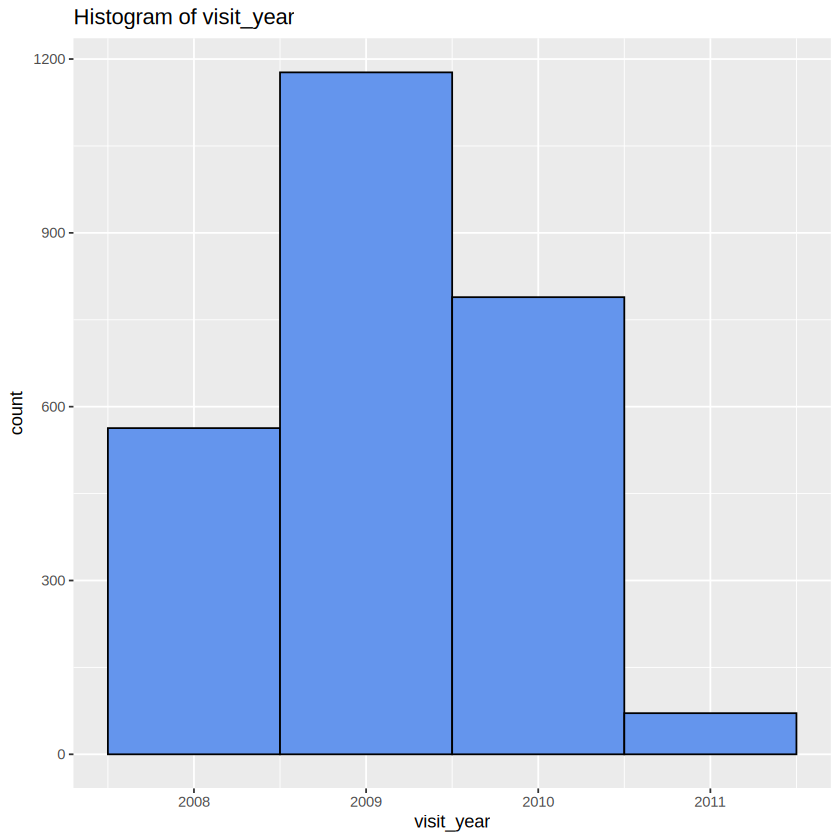

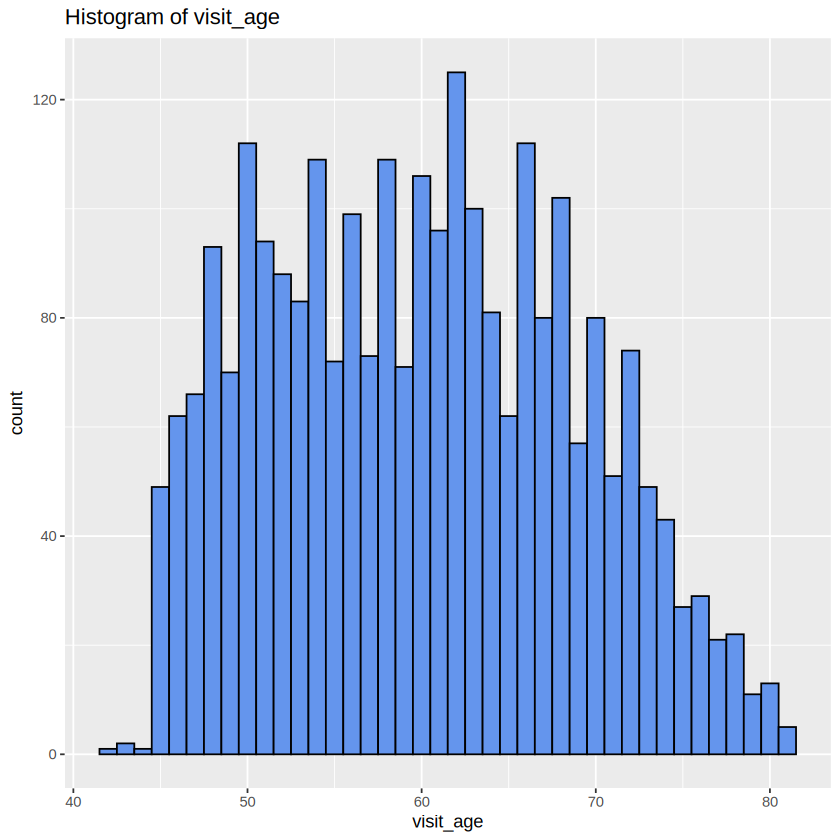

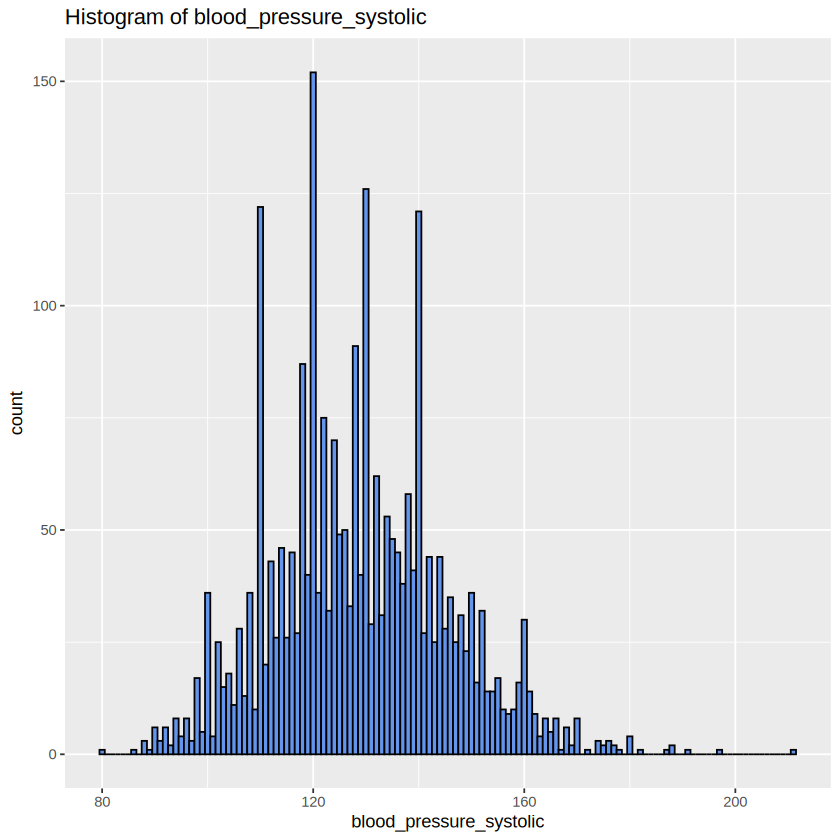

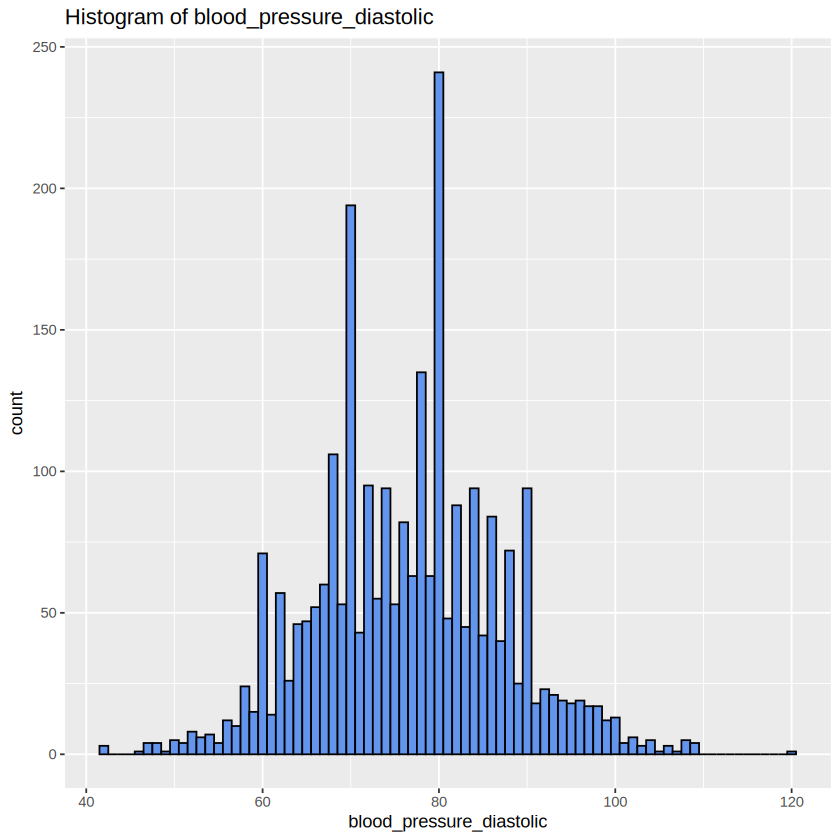

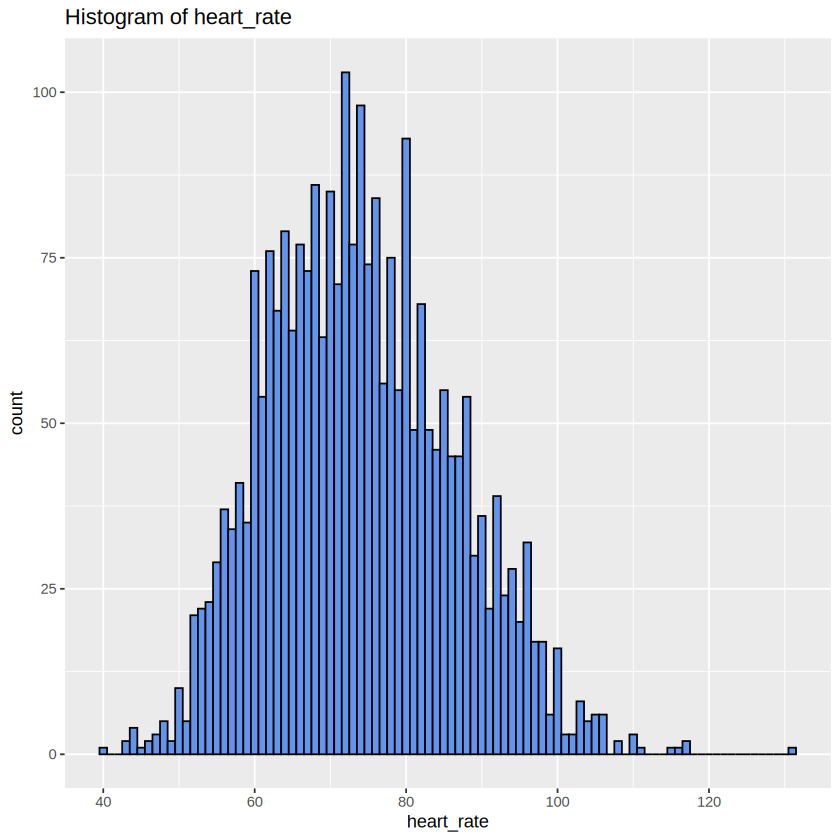

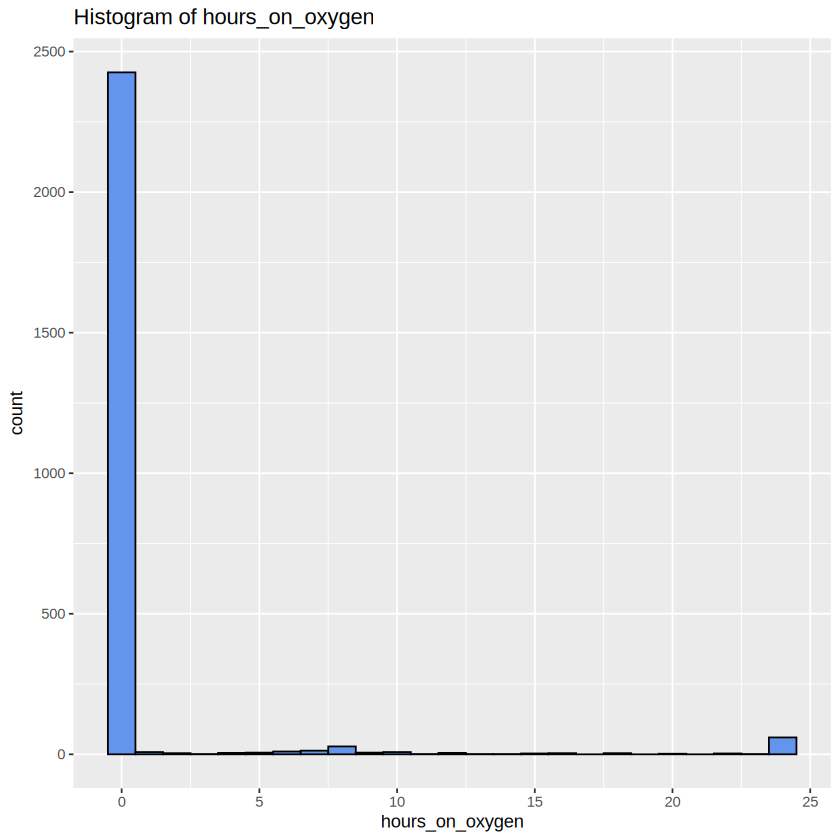

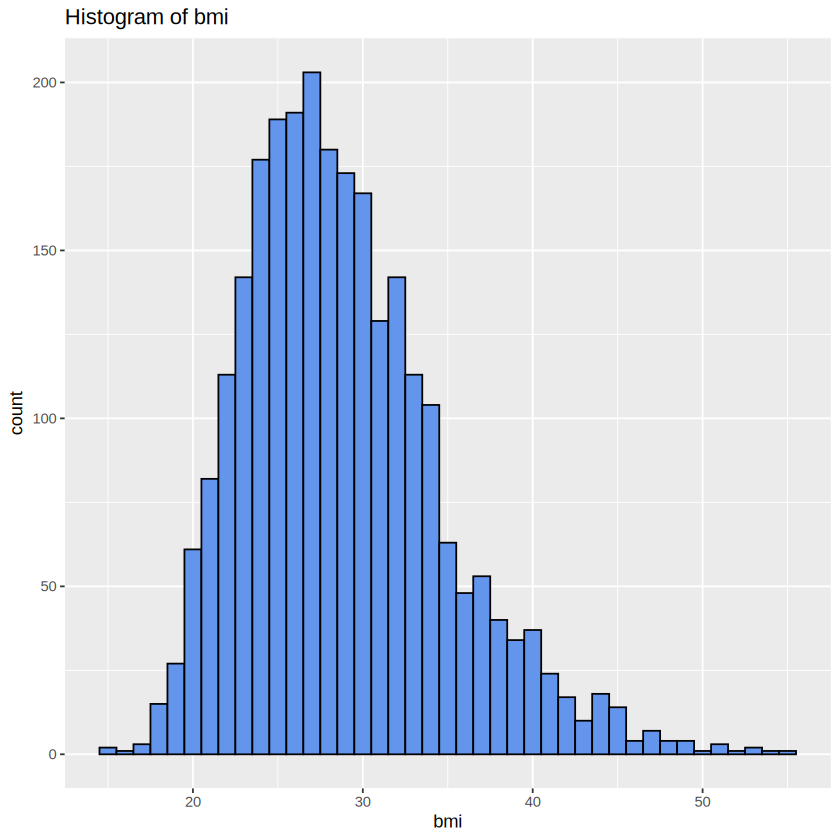

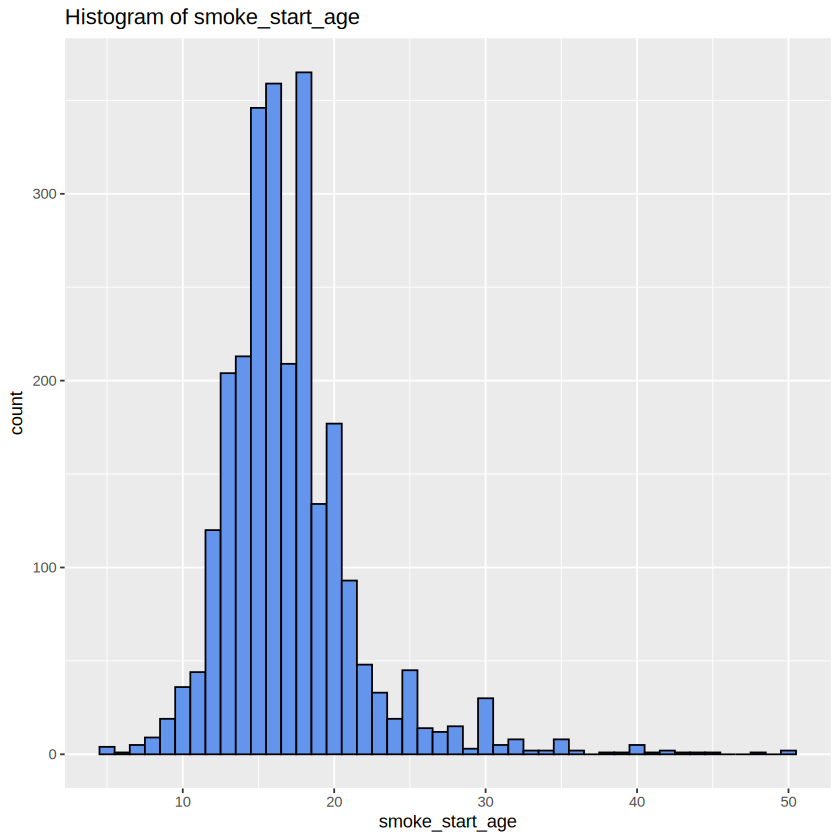

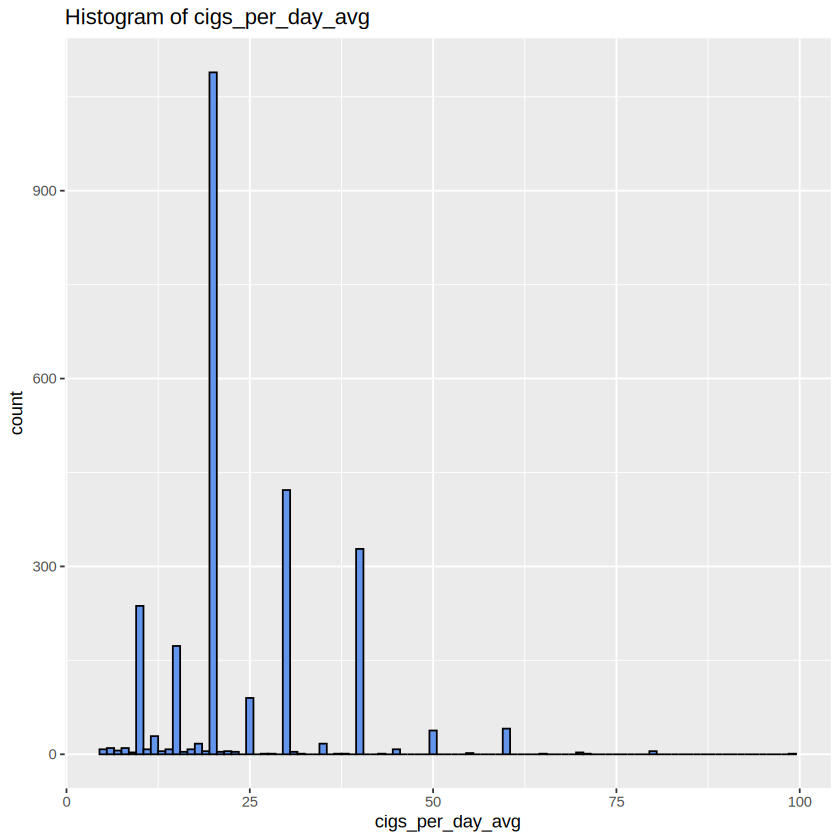

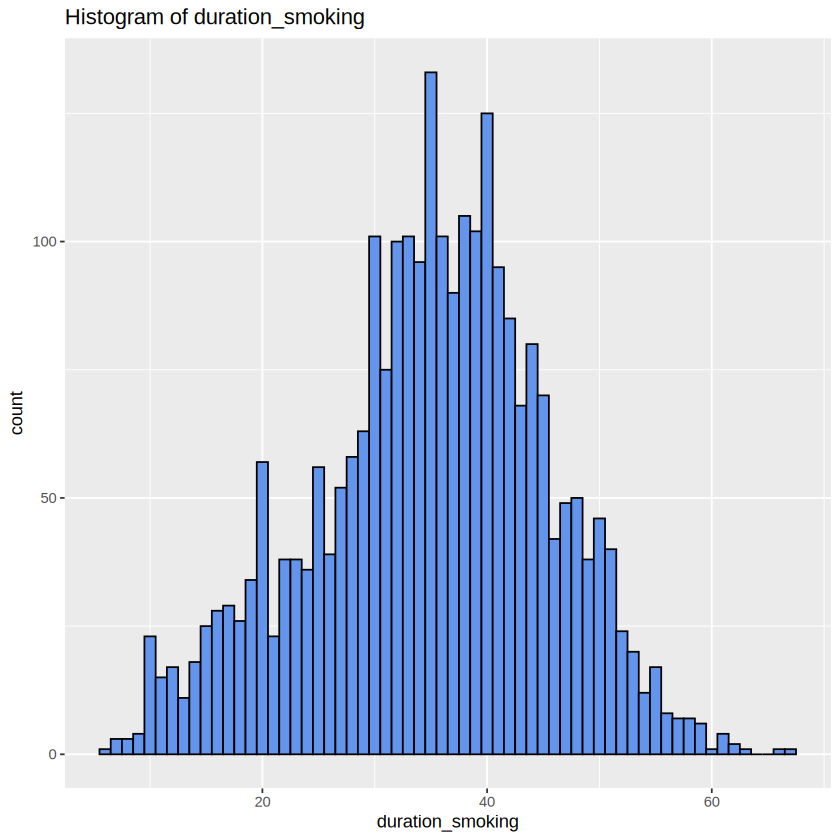

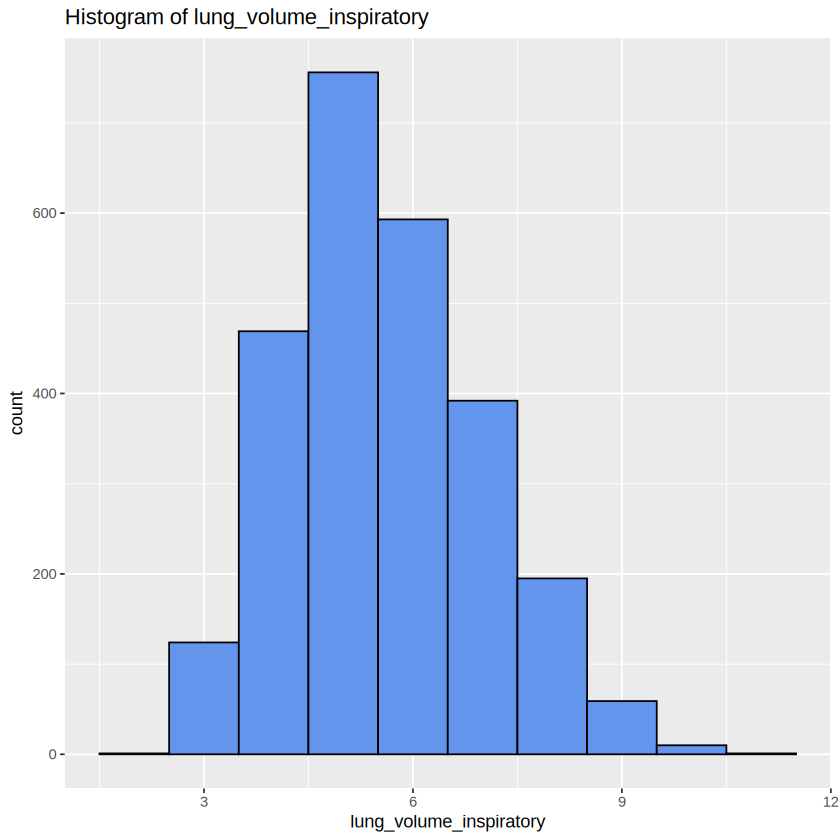

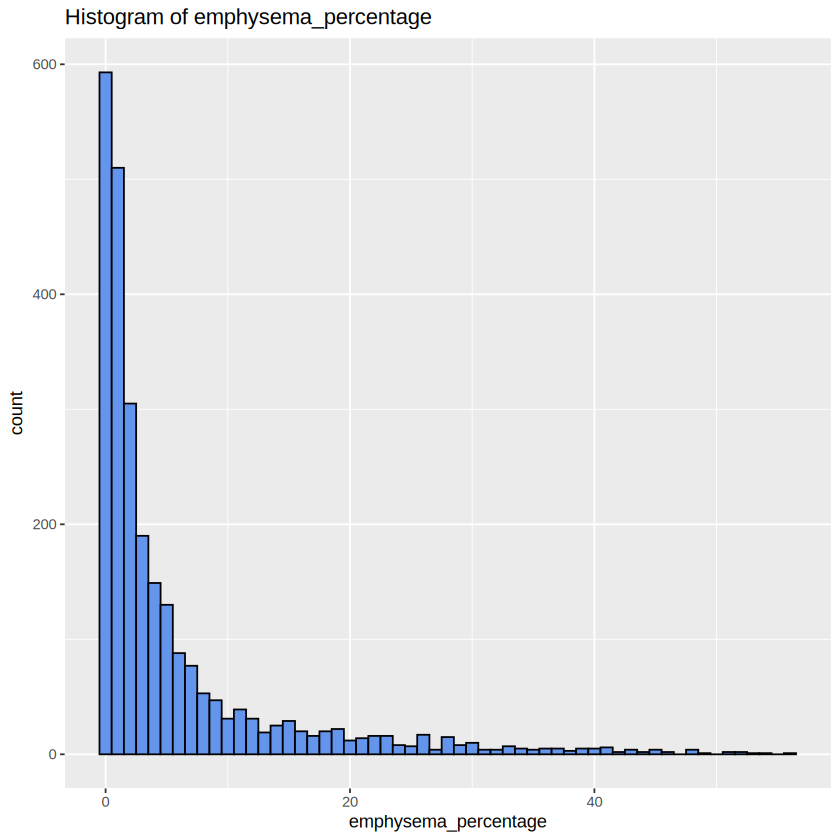

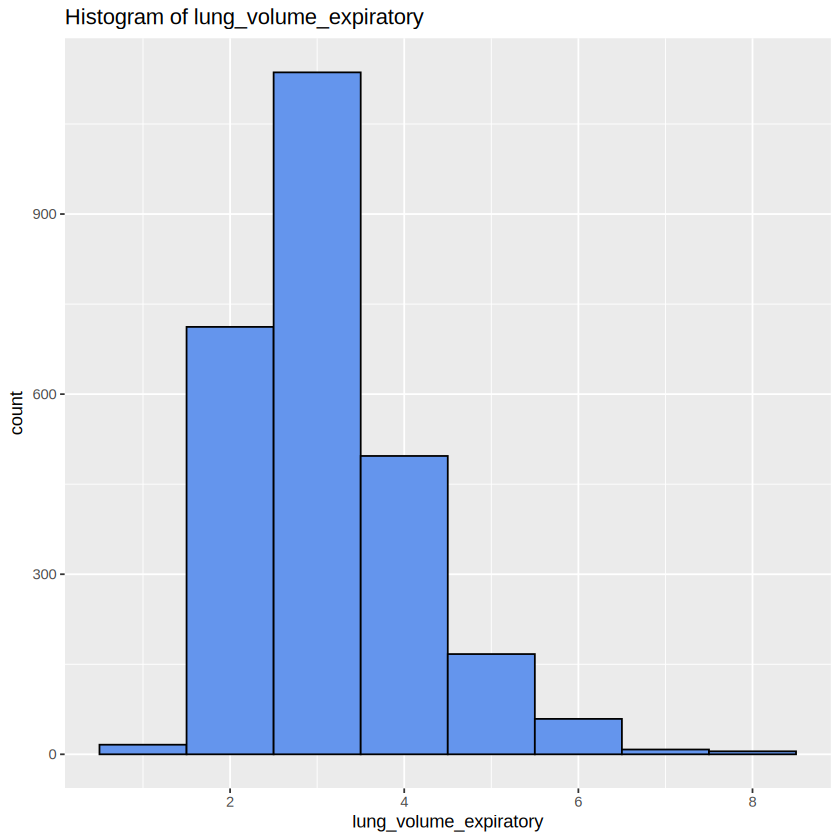

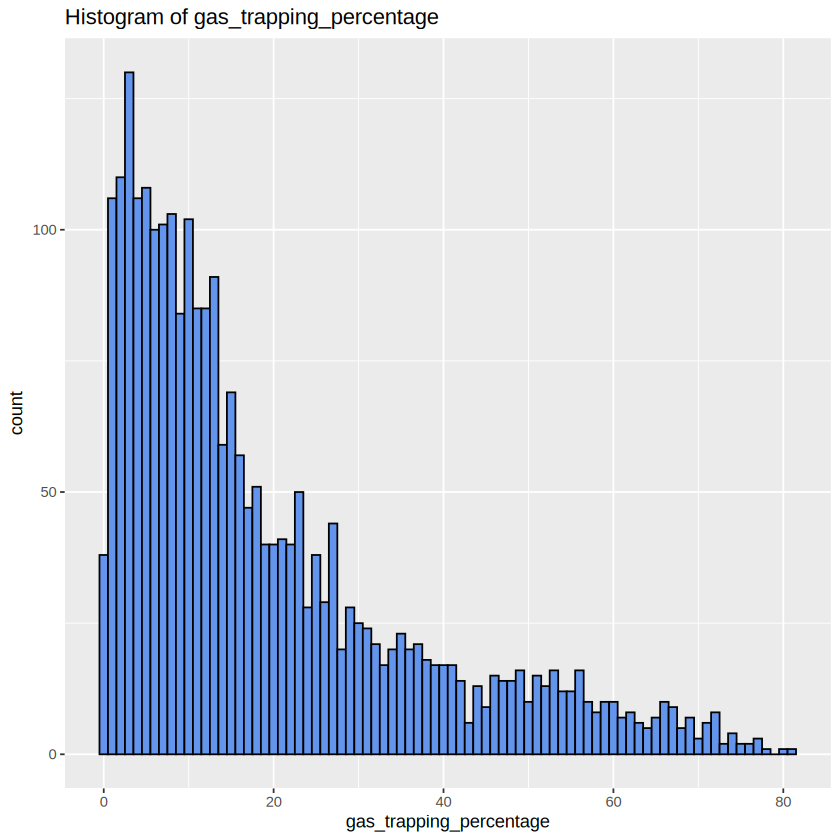

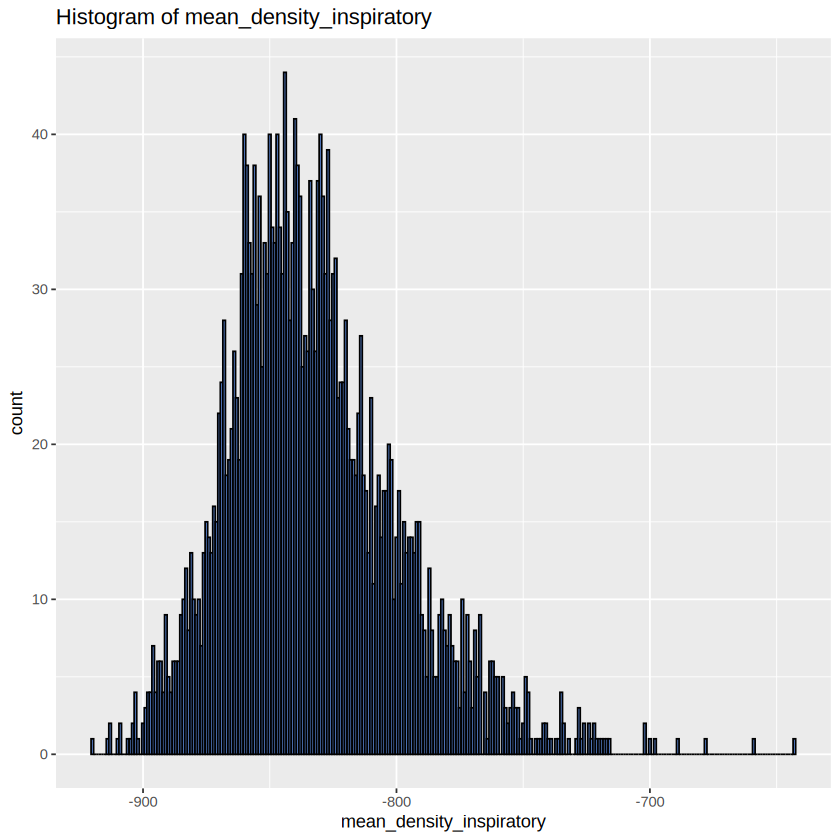

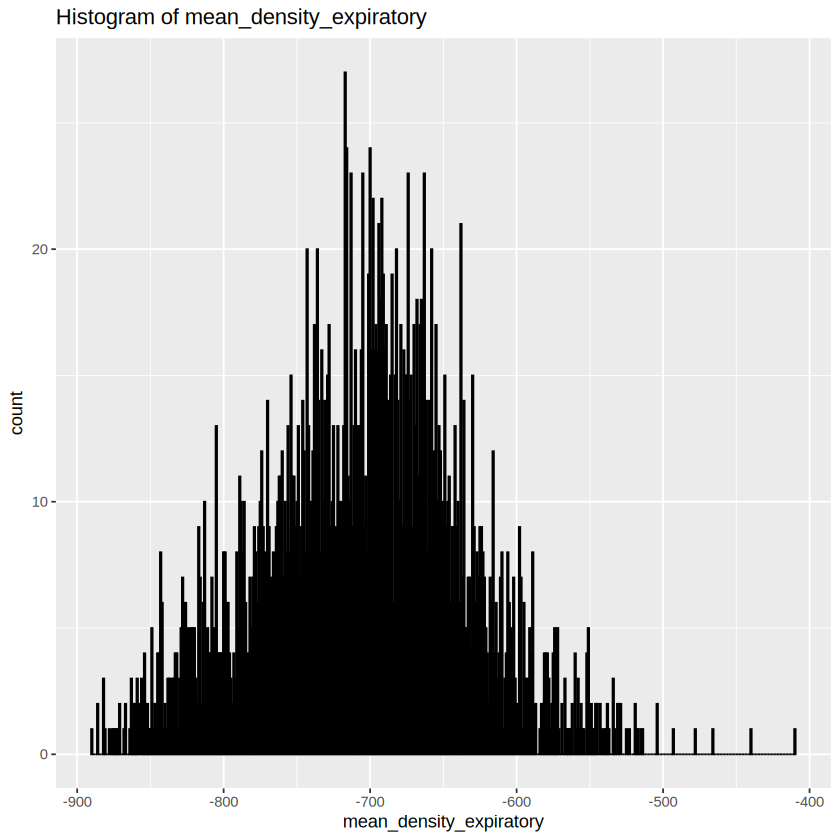

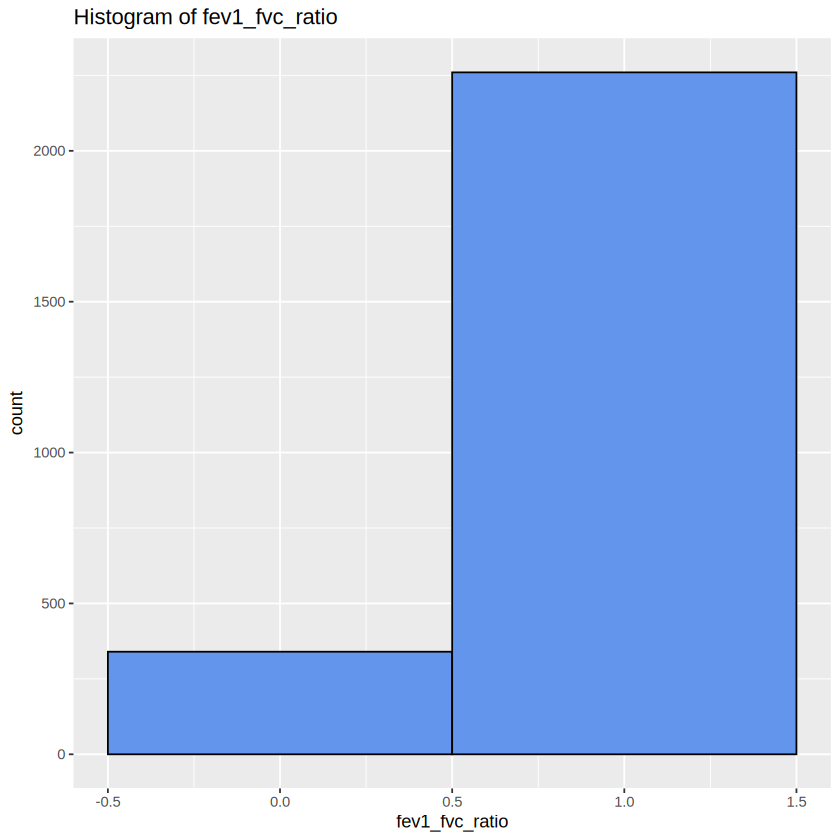

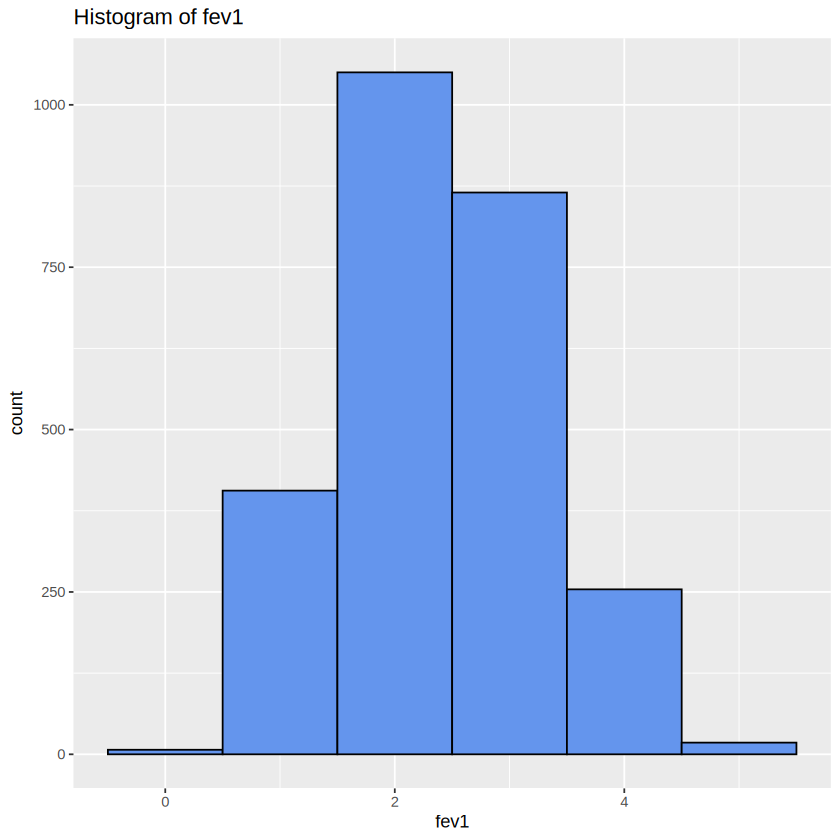

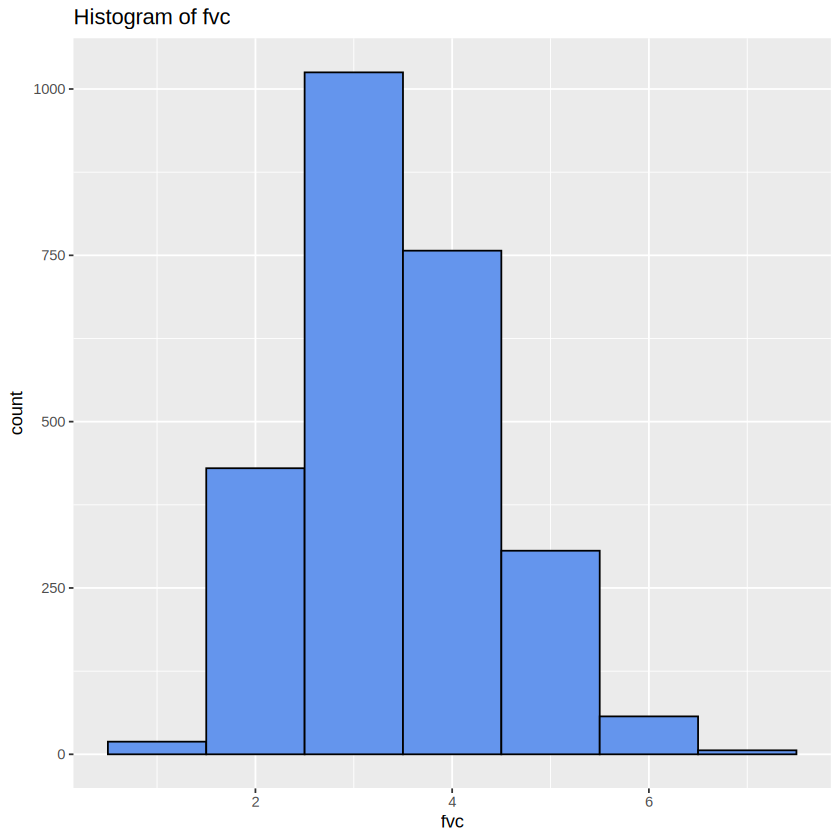

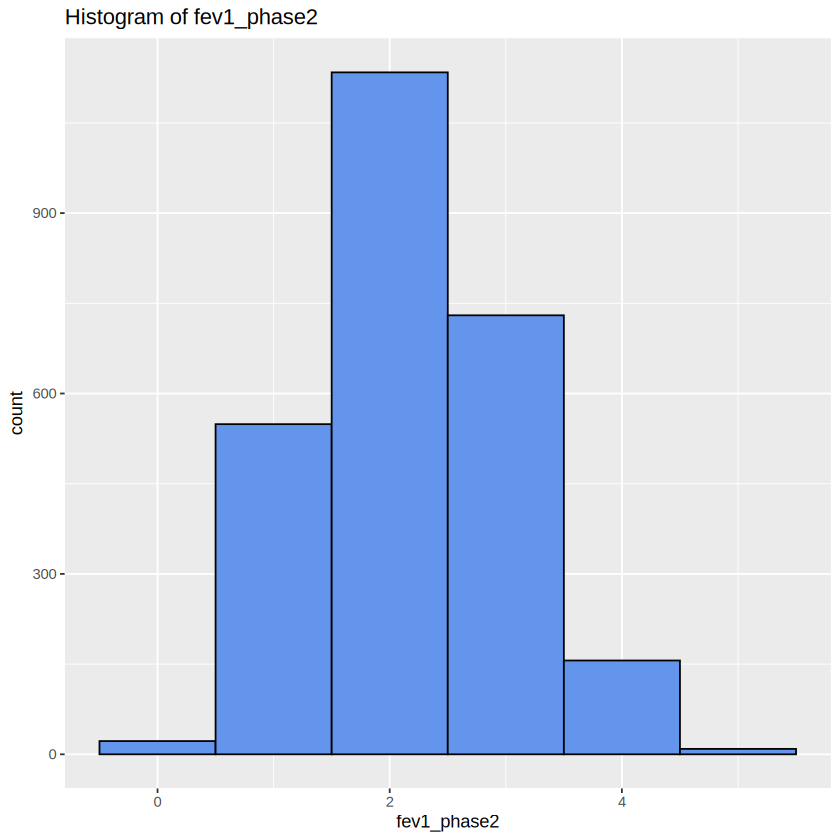

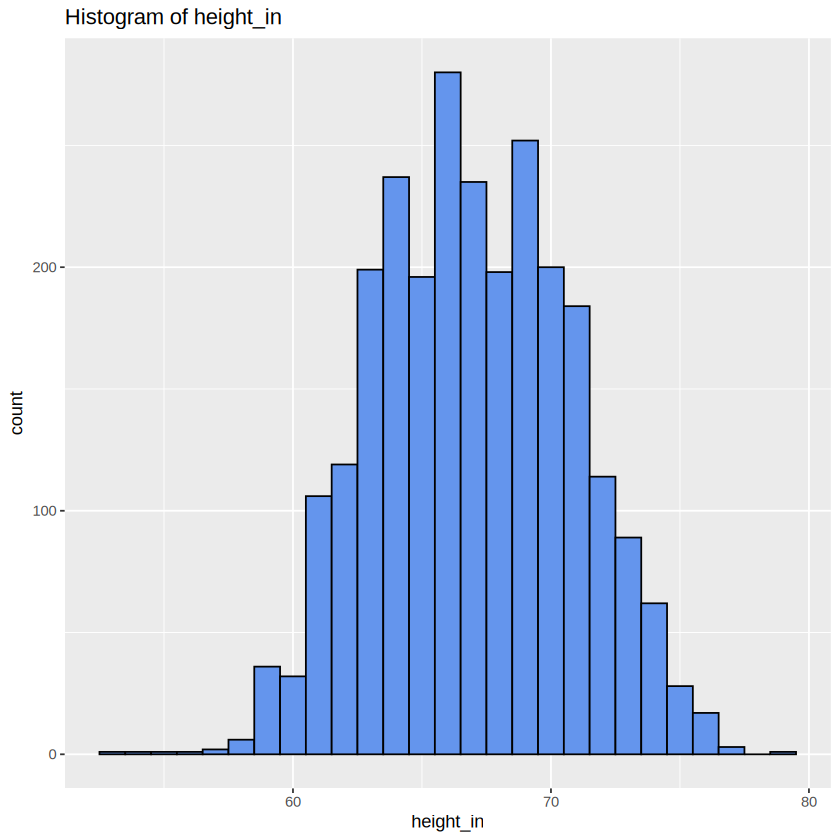

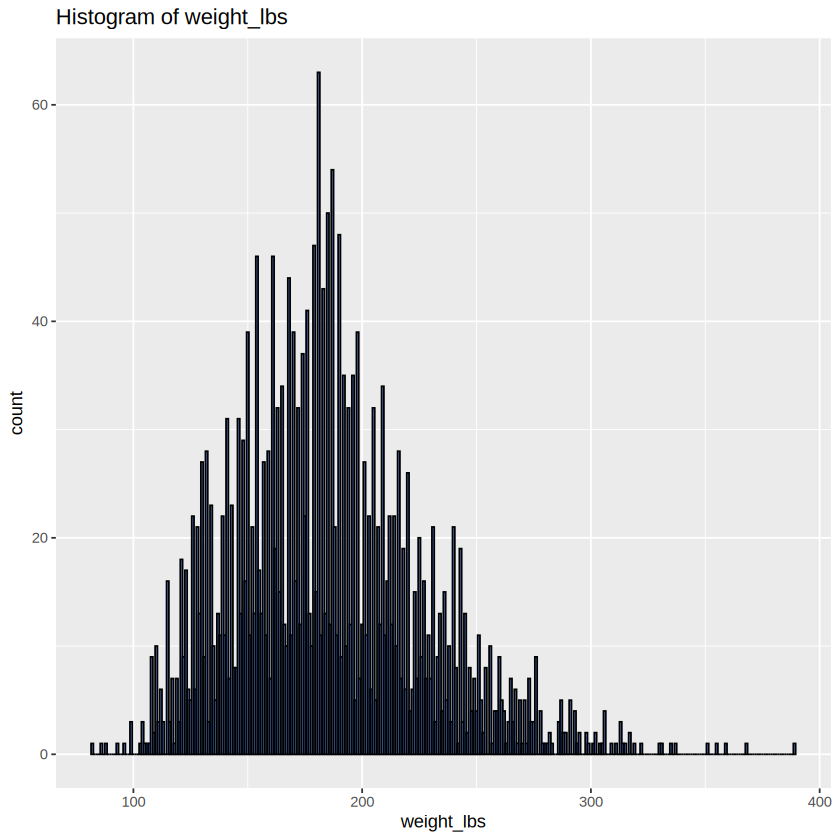

In [13]:
# use a loop for each column
for (col_name in names(final_merged)) {
  # check if variable is numeric/int
  if (is.numeric(final_merged[[col_name]]) || is.integer(final_merged[[col_name]])) {
    print(
      ggplot(final_merged, aes_string(x = col_name)) +
        geom_histogram(binwidth = 1, fill = "cornflowerblue", color = "black") +
        ggtitle(paste("Histogram of", col_name))
    )
  }
}

#Task 10:

#The skewed variables are blood_pressure_systolic(right),
#hours_on_oxygen (right; barely any other points), bmi (right),
#smoke_start age (right), cigs_per_day_avg (right), emphysema percentage (right),
#lung_volume_expiratory(right), gas_trapping_percentage(right),
#weight_lbs(right), and fev1_fvc_ratio(left)

Warning message:
“Removed 2426 rows containing non-finite outside the scale range (`stat_bin()`).”


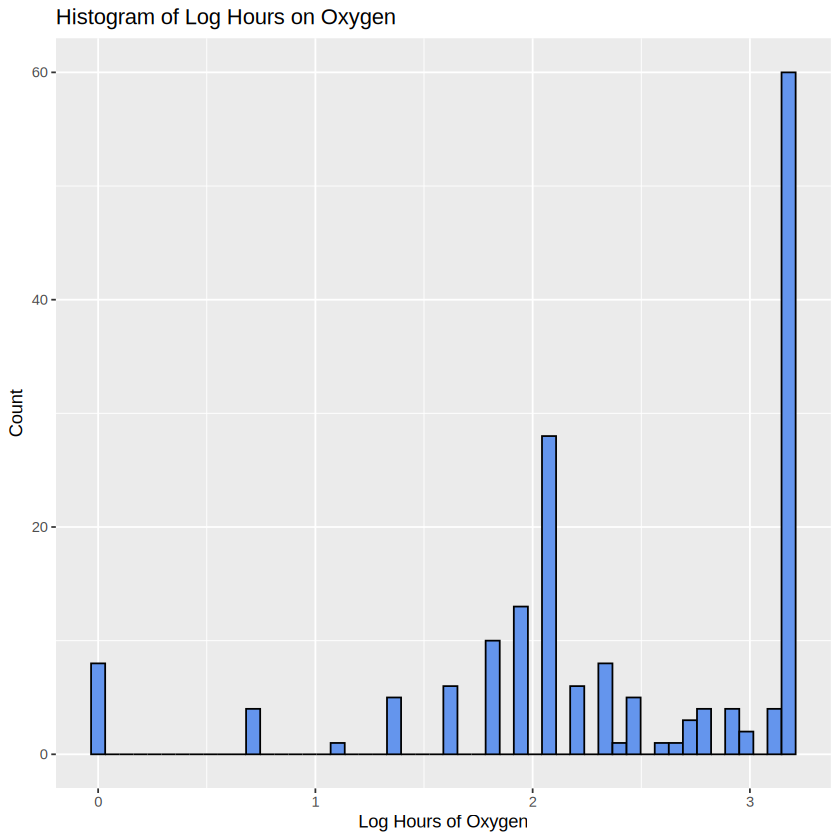

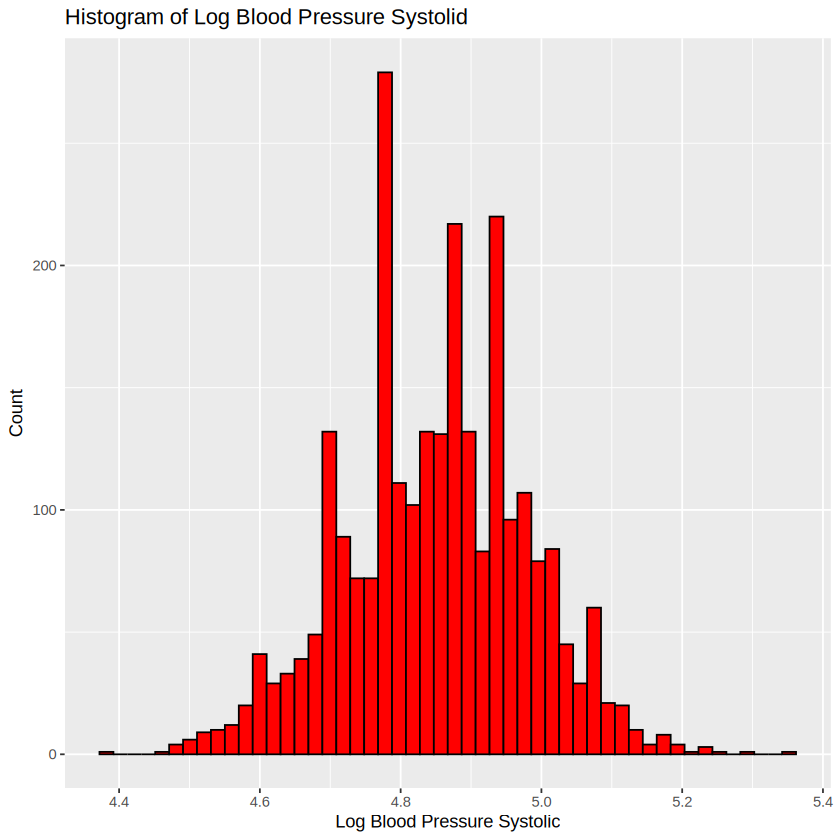

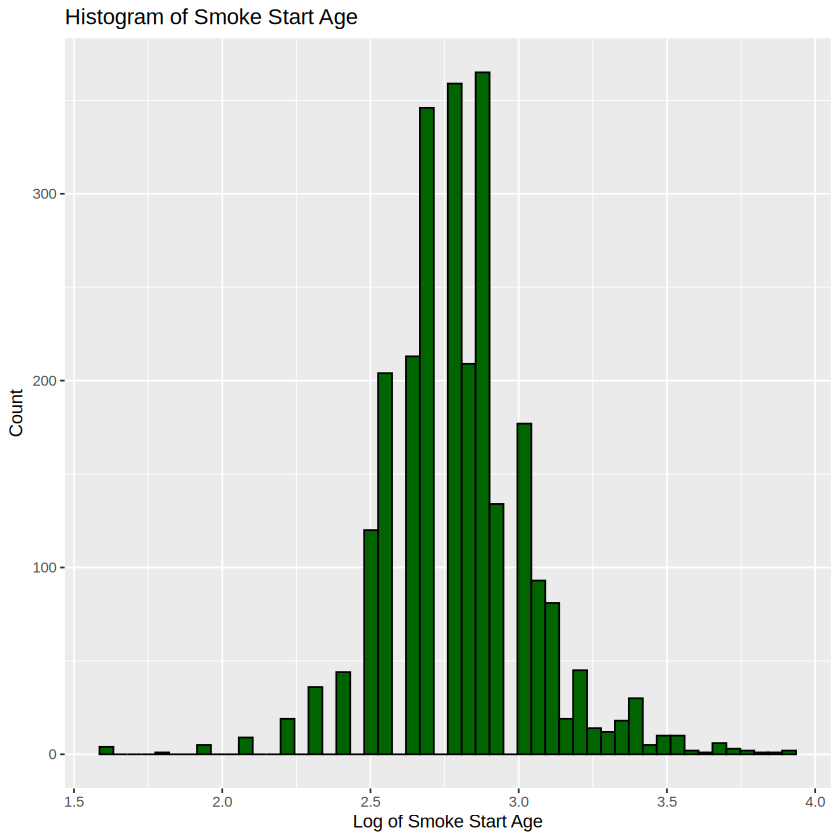

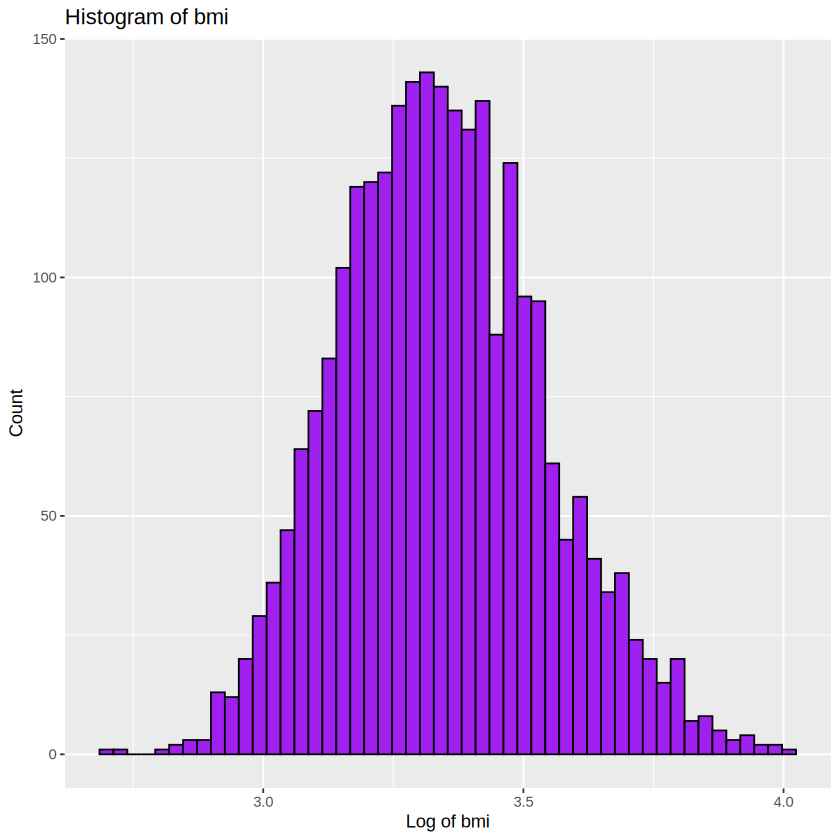

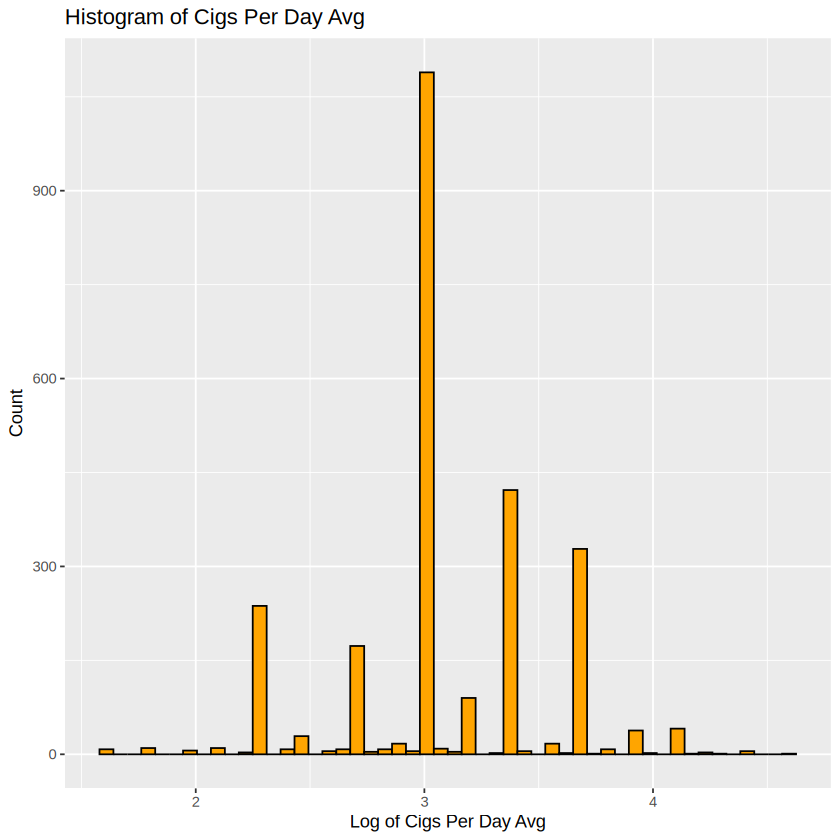

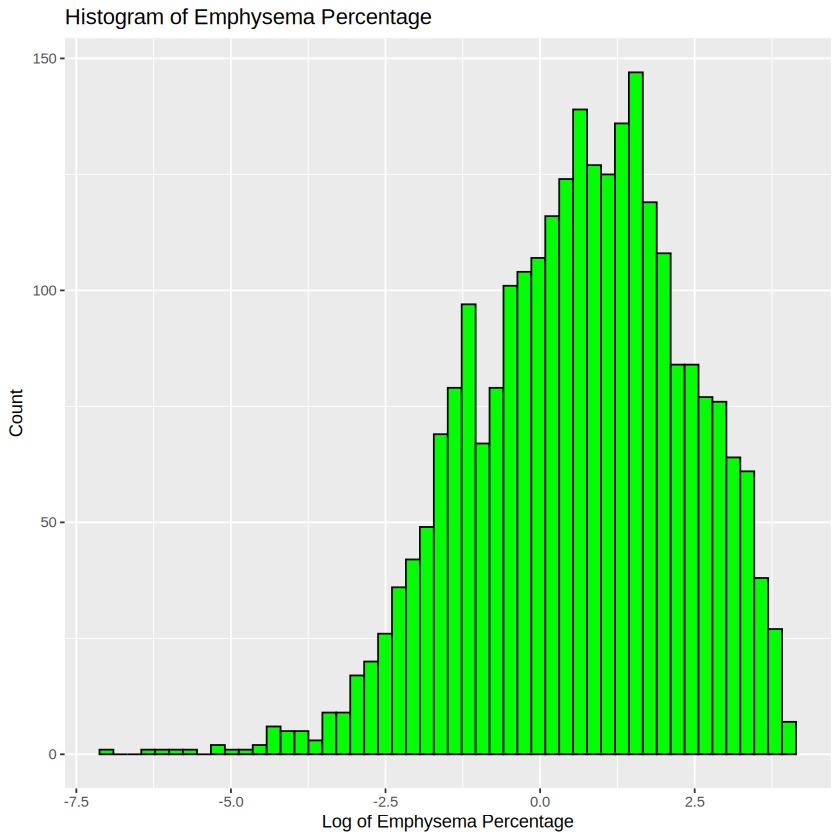

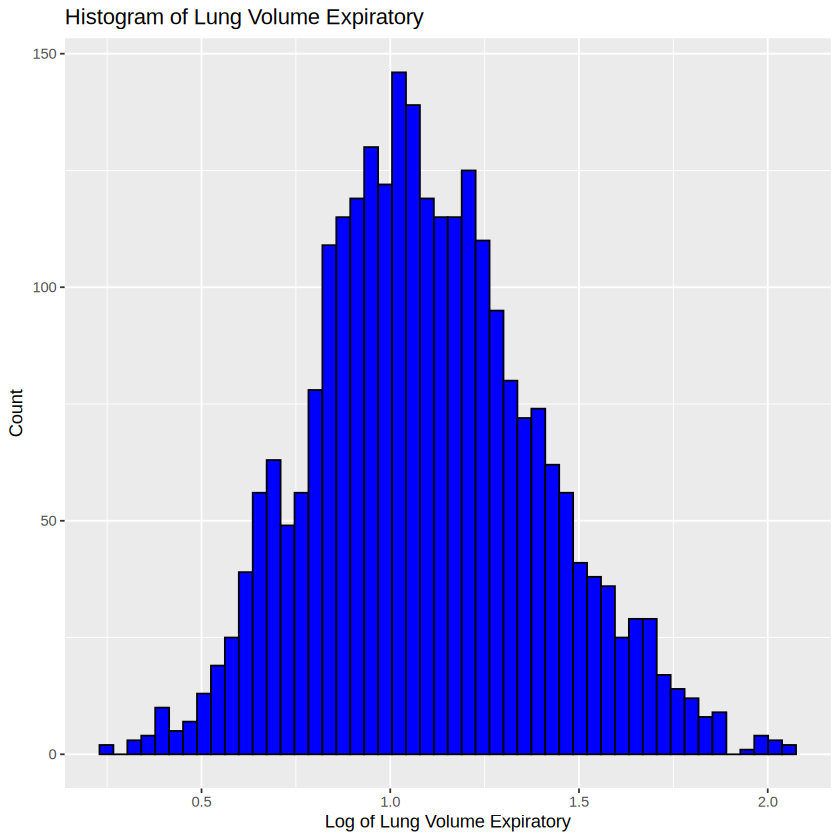

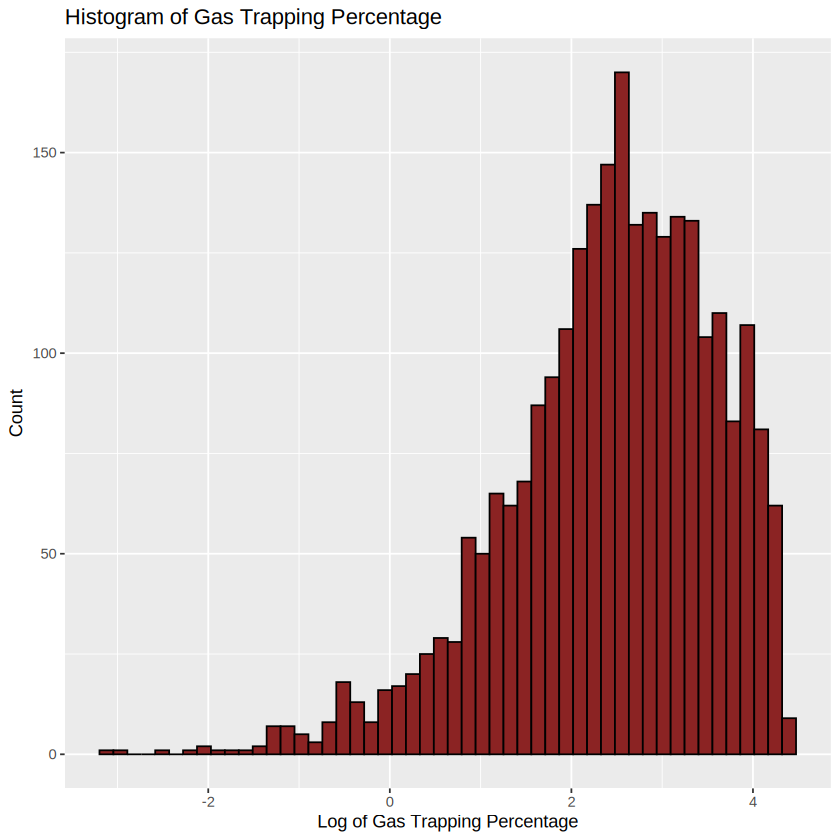

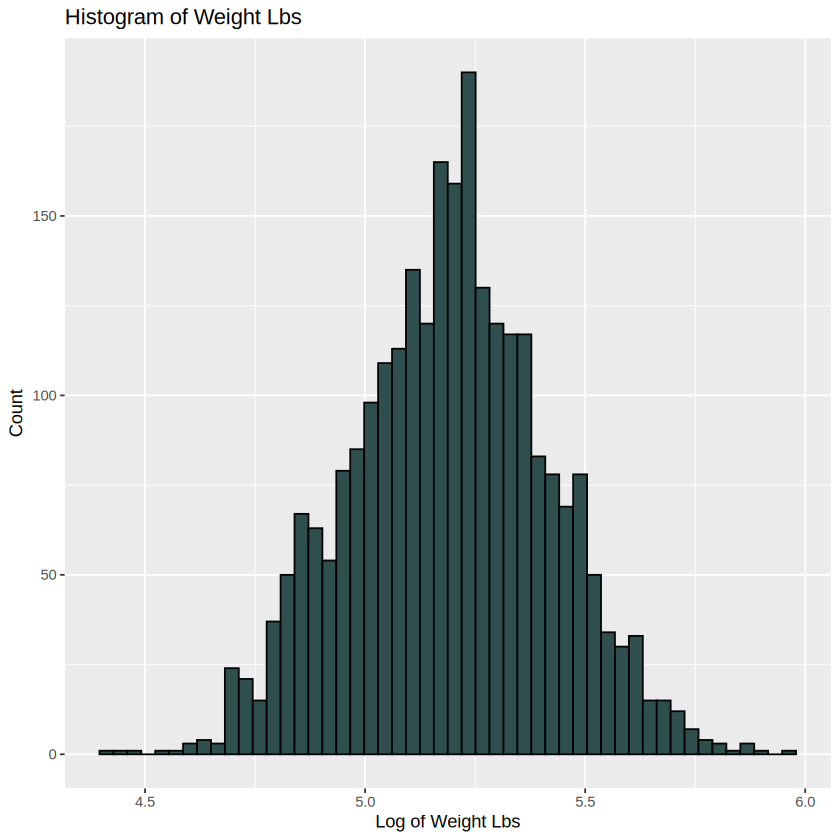

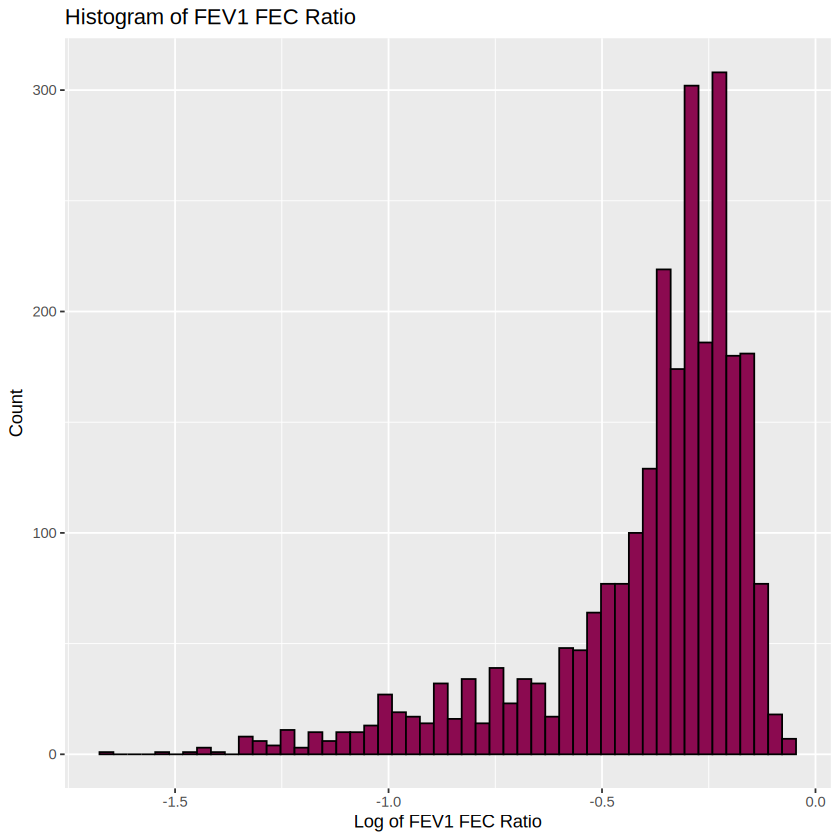

In [14]:
# log all the skewed variabes and make new histograms using the log variables
# log for transformations
final_merged$log_ox <- log(final_merged$hours_on_oxygen)
ggplot(data = final_merged, aes(x = log_ox)) +
  geom_histogram(bins = 50, fill = "cornflowerblue", color = "black") +
  labs(title = "Histogram of Log Hours on Oxygen",
       x     = "Log Hours of Oxygen",
       y     = "Count")

final_merged$log_sys <- log(final_merged$blood_pressure_systolic)
ggplot(data = final_merged, aes(x = log_sys)) +
  geom_histogram(bins = 50, fill = "red", color = "black") +
  labs(title = "Histogram of Log Blood Pressure Systolid",
       x     = "Log Blood Pressure Systolic",
       y     = "Count")

final_merged$log_smokeage <- log(final_merged$smoke_start_age)
ggplot(data = final_merged, aes(x = log_smokeage)) +
  geom_histogram(bins = 50,fill = "darkgreen", color = "black") +
  labs(title = "Histogram of Smoke Start Age",
       x     = "Log of Smoke Start Age",
       y     = "Count")

final_merged$log_bmi <- log(final_merged$bmi)
ggplot(data = final_merged, aes(x = log_bmi)) +
  geom_histogram(bins = 50, fill = "purple", color = "black") +
  labs(title = "Histogram of bmi",
       x     = "Log of bmi",
       y     = "Count")

final_merged$log_cigs <- log(final_merged$cigs_per_day_avg)
ggplot(data = final_merged, aes(x = log_cigs)) +
  geom_histogram(bins = 50, fill = "orange", color = "black") +
  labs(title = "Histogram of Cigs Per Day Avg",
       x     = "Log of Cigs Per Day Avg",
       y     = "Count")

final_merged$log_emphperc <- log(final_merged$emphysema_percentage)
ggplot(data = final_merged, aes(x = log_emphperc)) +
  geom_histogram(bins = 50, fill = "green", color = "black") +
  labs(title = "Histogram of Emphysema Percentage",
       x = "Log of Emphysema Percentage",
       y     = "Count")

final_merged$log_lungex <- log(final_merged$lung_volume_expiratory)
ggplot(data = final_merged, aes(x = log_lungex)) +
  geom_histogram(bins = 50, fill = "blue", color = "black") +
  labs(title = "Histogram of Lung Volume Expiratory",
       x = "Log of Lung Volume Expiratory",
       y     = "Count")

final_merged$log_gasperc <- log(final_merged$gas_trapping_percentage)
ggplot(data = final_merged, aes(x = log_gasperc)) +
  geom_histogram(bins = 50, fill = "brown4", color = "black") +
  labs(title = "Histogram of Gas Trapping Percentage",
       x = "Log of Gas Trapping Percentage",
       y     = "Count")

final_merged$log_weightlbs <- log(final_merged$weight_lbs)
ggplot(data = final_merged, aes(x = log_weightlbs)) +
  geom_histogram(bins = 50, fill = "darkslategrey", color = "black") +
  labs(title = "Histogram of Weight Lbs",
       x = "Log of Weight Lbs",
       y     = "Count")

final_merged$log_fev1rat <- log(final_merged$fev1_fvc_ratio)
ggplot(data = final_merged, aes(x = log_fev1rat)) +
  geom_histogram(bins = 50,fill = "deeppink4", color = "black") +
  labs(title = "Histogram of FEV1 FEC Ratio",
       x = "Log of FEV1 FEC Ratio",
       y     = "Count")


<br>

<br>

<br>

---

<br>






####<font color=red>Task 11</font>

We are primarily interested in the breathing function of the clinical trial participants after five years (`fev1_phase2`).

Using `ggplot` covered in the course,

1. Visualize the relationship between `fev1_phase2` and at least five categorical variables in your data frame

2. What are your observations? Based on your data visualizations, do there appear to be any differences in `fev1_phase2` between groups?

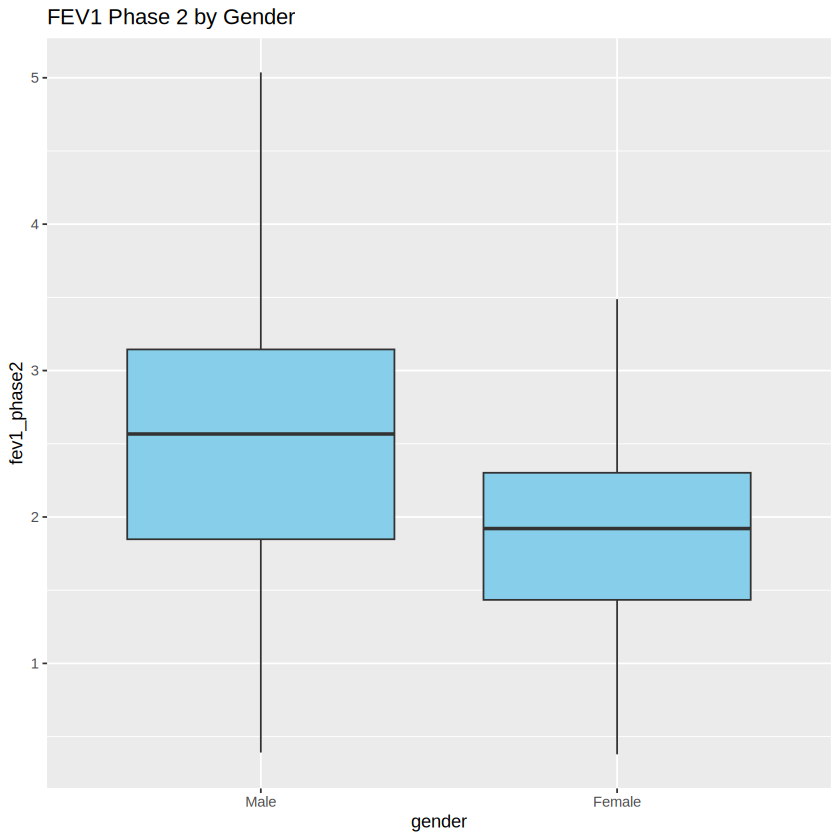

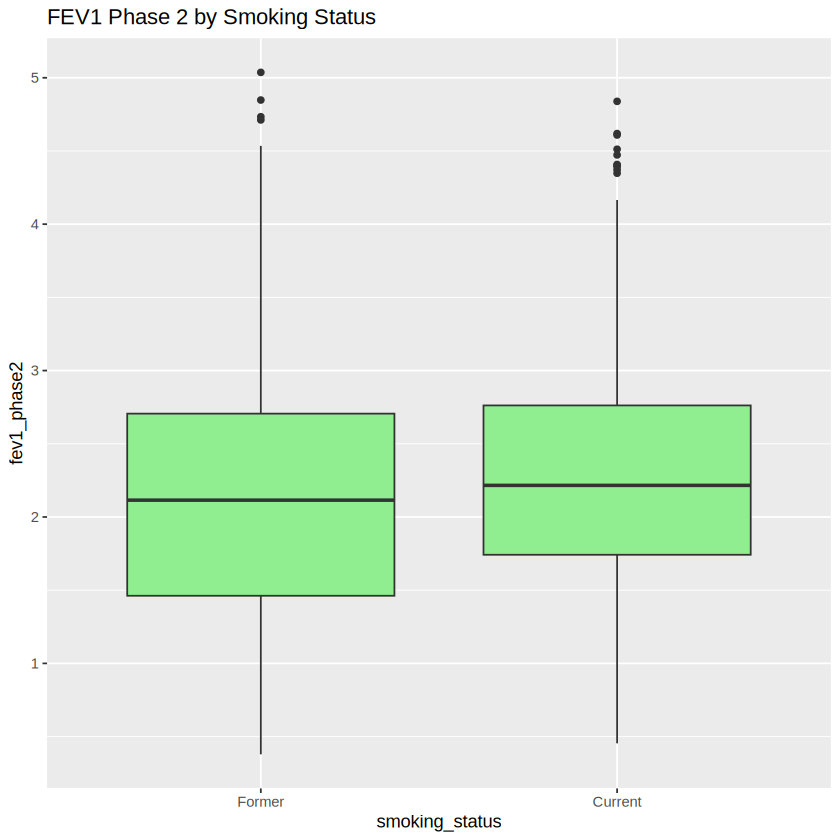

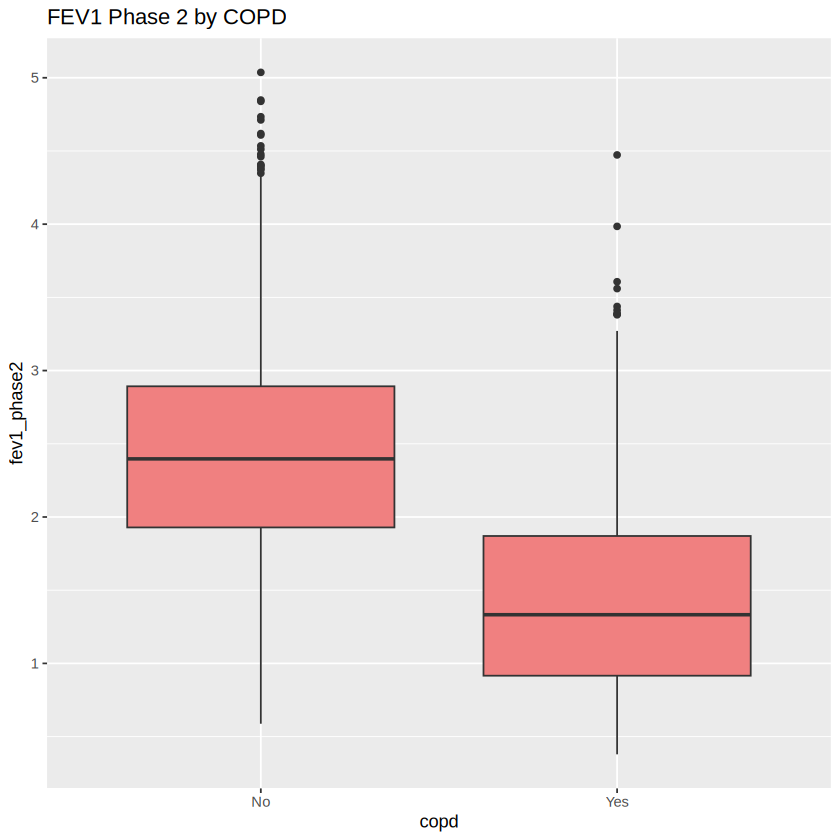

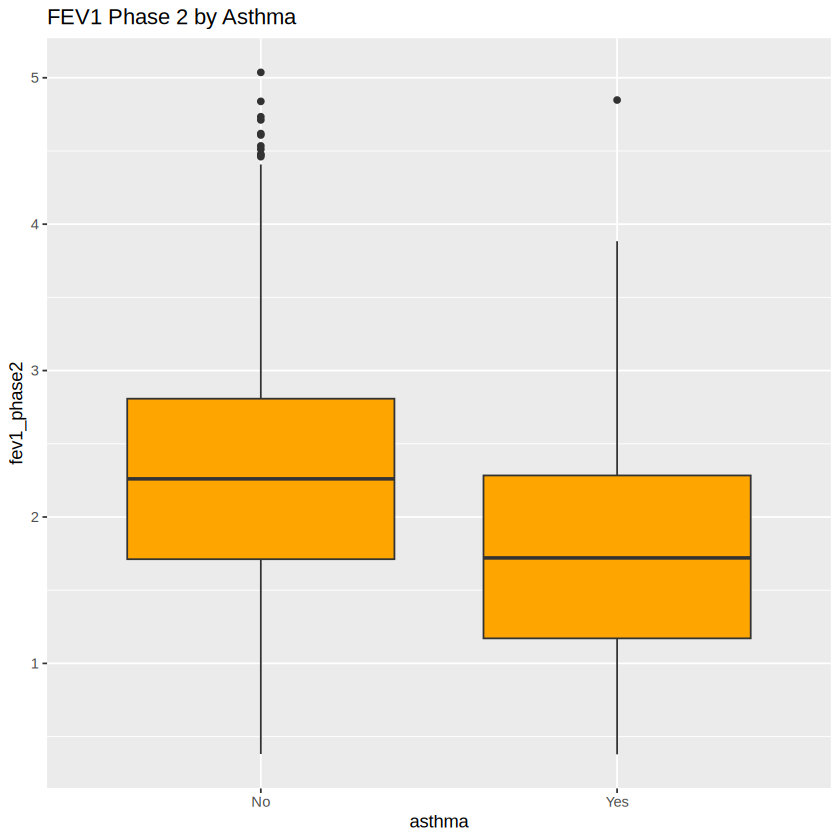

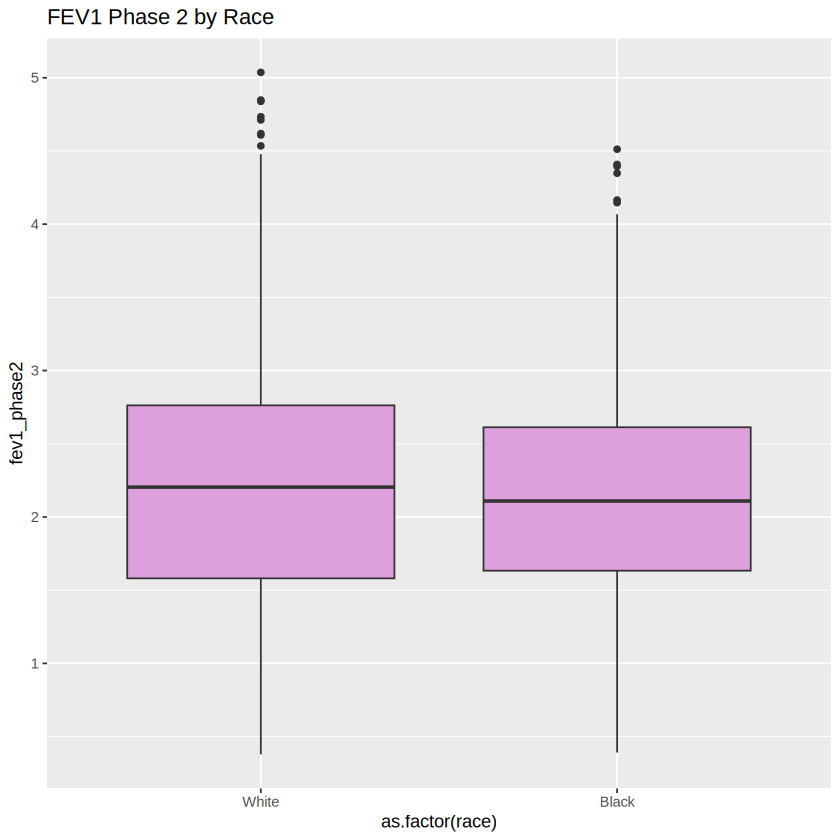

In [15]:
# gender
ggplot(final_merged, aes(x = gender, y = fev1_phase2)) +
  geom_boxplot(fill = "skyblue") +
  labs(title = "FEV1 Phase 2 by Gender")

# smoking_status
ggplot(final_merged, aes(x = smoking_status, y = fev1_phase2)) +
  geom_boxplot(fill = "lightgreen") +
  ggtitle("FEV1 Phase 2 by Smoking Status")

# copd
ggplot(final_merged, aes(x = copd, y = fev1_phase2)) +
  geom_boxplot(fill = "lightcoral") +
  ggtitle("FEV1 Phase 2 by COPD")

# asthma
ggplot(final_merged, aes(x = asthma, y = fev1_phase2)) +
  geom_boxplot(fill = "orange") +
  ggtitle("FEV1 Phase 2 by Asthma")

# race
ggplot(final_merged, aes(x = as.factor(race), y = fev1_phase2)) +
  geom_boxplot(fill = "plum") +
  ggtitle("FEV1 Phase 2 by Race")


Task 11:

It looks like there are some differences by using the median of the boxplots. FEV1 5 years later, men have more volume of air forcefully exhaled after one second than women. Former smokers are able to have more volume of air forcefully exhaled after one second than current smokers. However, there is not a large noticeable difference between the two. People with chronic bronchitis pulmonary disorder (COPD) are not as capable of having more volume of air forcefully exhaled after one second than those without COPD. Those without asthma are more likely to have more volume of air forcefully exhaled after one second than those without asthma. White people are slightly more likely to have more volume of air forcefully exhaled after one second, however, there is not a large noticeable difference between the two.

<br>

<br>

<br>

---

<br>






####<font color=red>Task 12</font>

We are primarily interested in the breathing function of the clinical trial participants after five years (`fev1_phase2`).

Using `ggplot` covered in the course,

1. Visualize the relationship between `fev1_phase2` and at least ***five*** numeric variables in your data frame

2. What are your observations? Based on your data visualizations, does there appear to be any relationships between these variables and `fev1_phase2`? Are these relationships linear? something else?

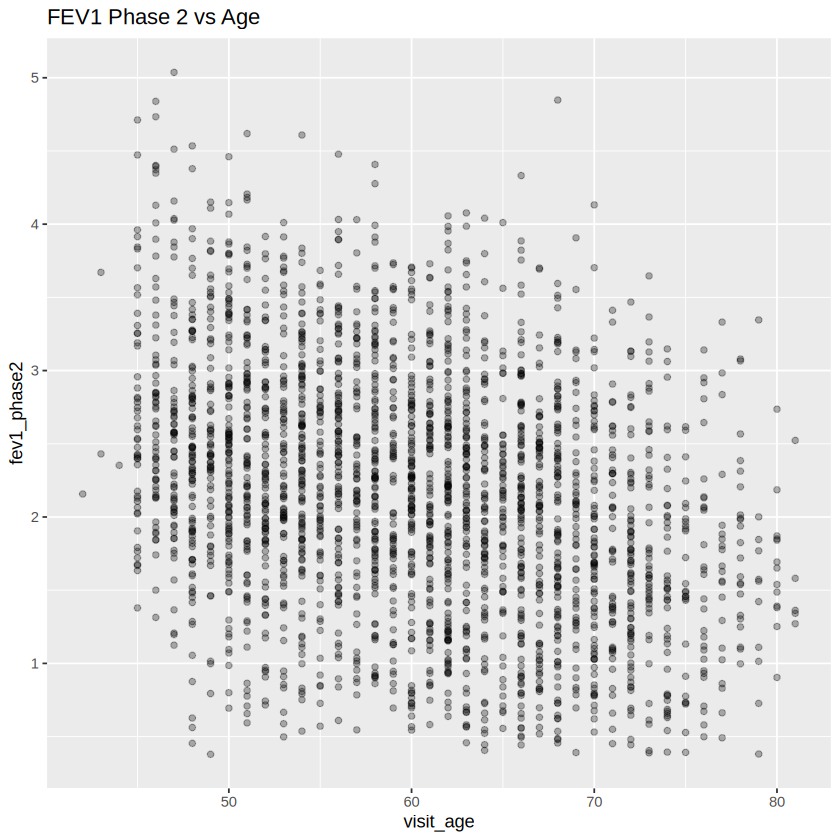

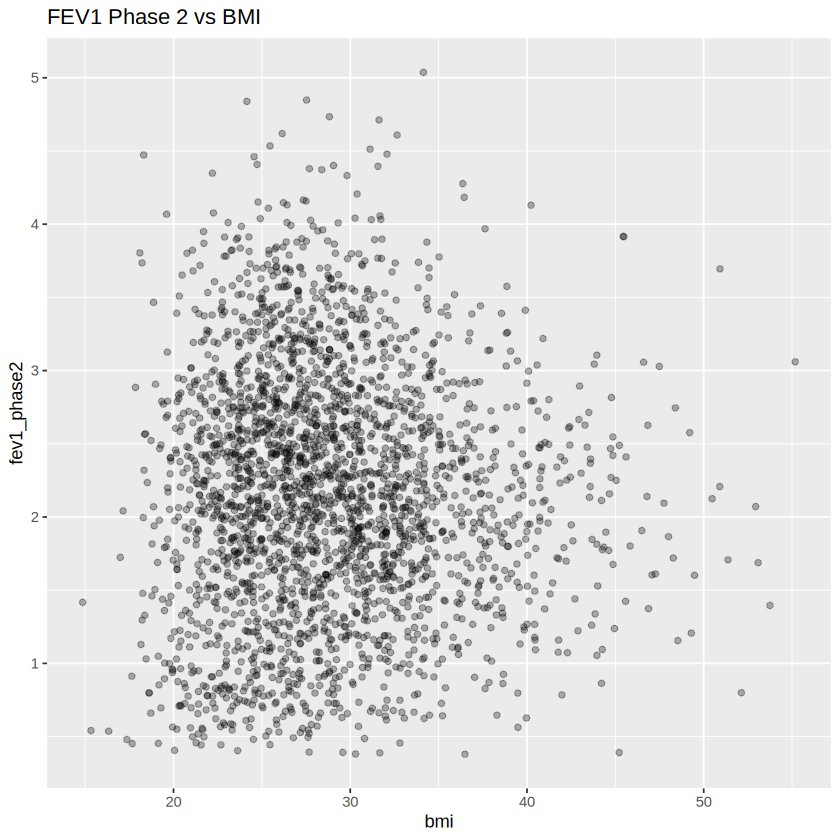

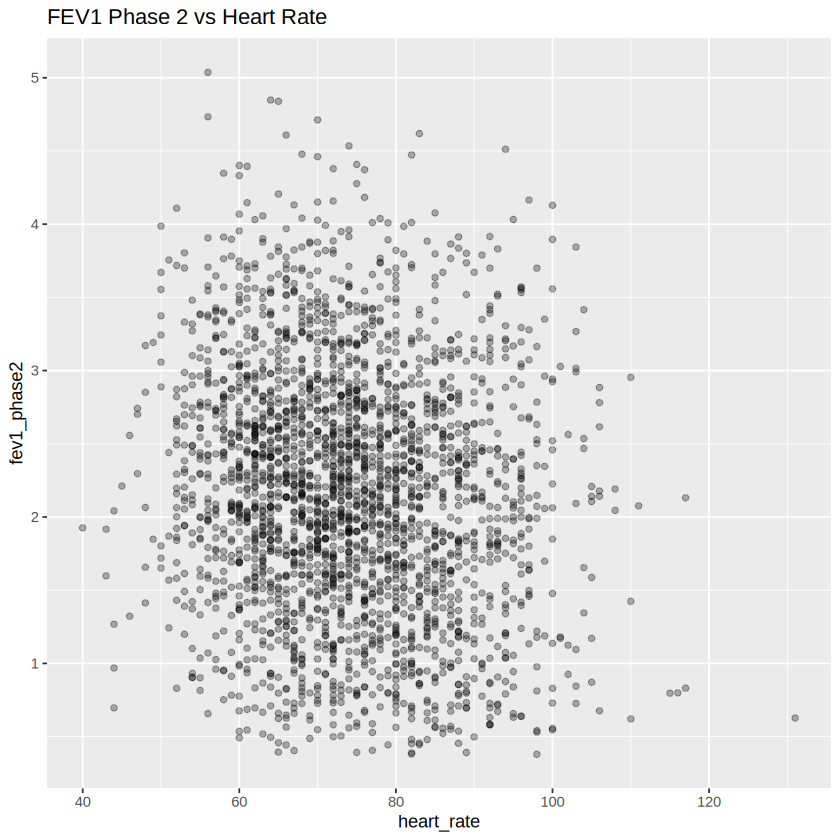

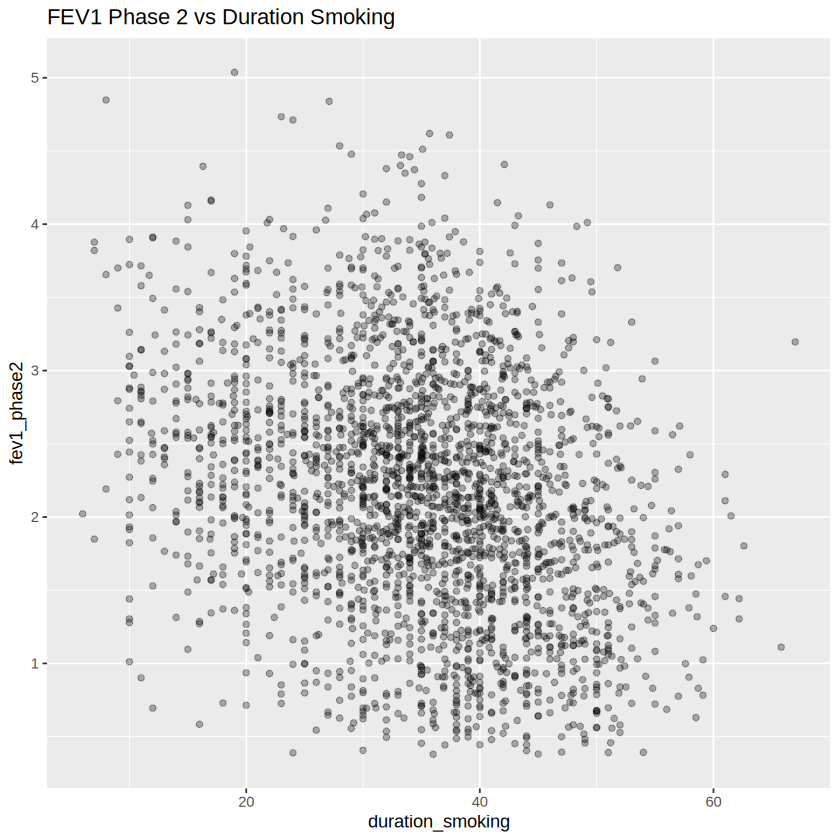

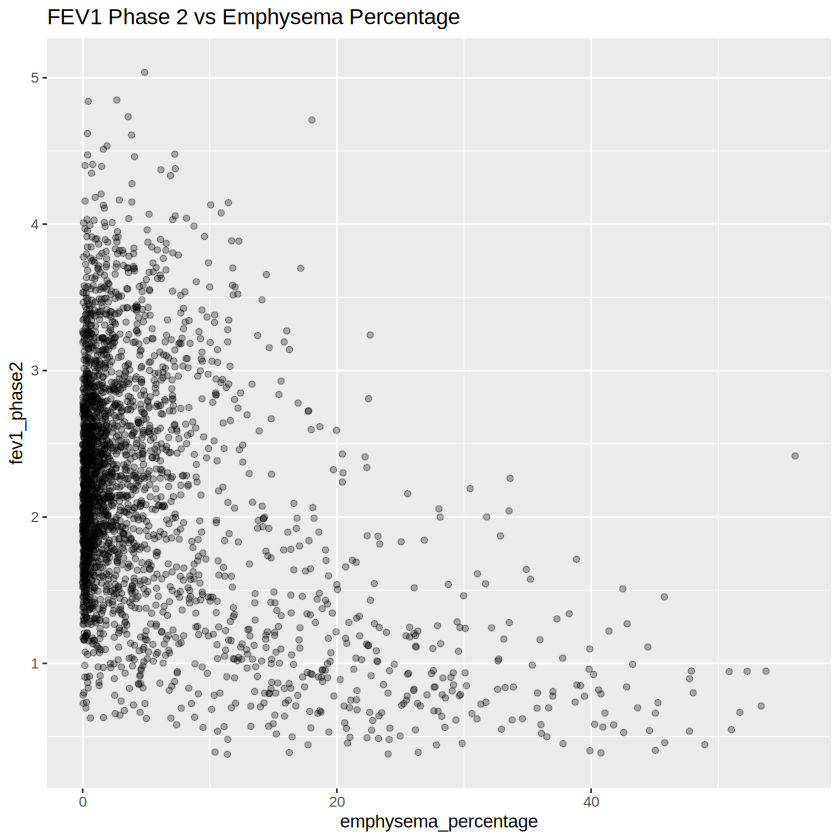

In [16]:
# fev1_phase2 vs age
ggplot(final_merged, aes(x = visit_age, y = fev1_phase2)) +
  geom_point(alpha = 0.3) +
  ggtitle("FEV1 Phase 2 vs Age")

# fev1_phase2 vs BMI
ggplot(final_merged, aes(x = bmi, y = fev1_phase2)) +
  geom_point(alpha = 0.3) +
  ggtitle("FEV1 Phase 2 vs BMI")

# fev1_phase2 vs Heart Rate
ggplot(final_merged, aes(x = heart_rate, y = fev1_phase2)) +
  geom_point(alpha = 0.3) +
  ggtitle("FEV1 Phase 2 vs Heart Rate")

# fev1_phase2 vs Duration Smoking
ggplot(final_merged, aes(x = duration_smoking, y = fev1_phase2)) +
  geom_point(alpha = 0.3) +
  ggtitle("FEV1 Phase 2 vs Duration Smoking")

# fev1_phase2 vs Emphysema %
ggplot(final_merged, aes(x = emphysema_percentage, y = fev1_phase2)) +
  geom_point(alpha = 0.3) +
  ggtitle("FEV1 Phase 2 vs Emphysema Percentage")


Task 12:


It looks like there is a slight negative correlation between age and FEV1 Phase 2. Those that are older (60+) end up exhaling less volume of air forcefully exhaled after one second than younger people (before 60). There is no clear linear pattern and little to no relationship for BMI to FEV1 Phase 2. This may indicate that BMI is not a great predictor for FEV1 Phase 2. For heart rate, there is no clear positive or negative trend; so, the correlation is quite weak and nonlinear. People that have smoked for longer periods of time will have a decreased volume of air forcefully exhaled after one second than people that have not been smoking as long. We can see this through the weak negative correlation, suggesting that the longer someone has been smoking (as time goes on), the lungs start to function worse. Subjects that have lower emphysema percentages are shown to have higher volume of air forcefully exhaled after one second than those with higher emphysema percentages. We can see this through the greatly right skewed data, as most of the data is towards the left and scatters loosely towards the right.


<br>

<br>

---






## Inference and Modeling

####<font color=red>Task 13</font>

Using code covered in the course,

1. Conduct a statistical test to determine if there is a significant difference in `fev1_phase2` between groups from your ***five*** categorical variables in Task 11.

In [17]:
# bootstrap sample size
B <- 2000

# function for group confidence interval
bootstrap_ci <- function(x) {
  n <- length(x) # sample size
  boot_means <- vector(length = B) #calculate bootstrap means
  for (i in 1:B) {
    boot_samp <- sample(x, size = n, replace = TRUE)  # bootstrap sample of size n
    boot_means[i] <- mean(boot_samp)   # store the bootstrap mean
  }
  quantile(boot_means, probs = c(0.025, 0.975)) # compute 95% confidence interval
}

# categorical variables from earlier
vars <- c("gender", "smoking_status", "copd", "asthma", "race")

# loop through each variable and compute confidence intervals for all groups
for (var in vars) {
  cat("\n\nBootstrap 95% CI for", var, "\n") #print all together
  levels <- unique(final_merged[[var]]) #make sure we get all the options in the variable

  # loop to print variable's confidence intervals
  for (lvl in levels) {
    group_data <- final_merged$fev1_phase2[final_merged[[var]] == lvl]
    ci <- bootstrap_ci(group_data)
    group_mean <- mean(group_data) #compute true mean of variable

    cat("Group:", lvl, "\n",
        "- Mean:", round(group_mean, 3), "\n",
        "- 95% CI:", round(ci[1], 3), "to", round(ci[2], 3), "\n")
  }
}




Bootstrap 95% CI for gender 
Group: Female 
 - Mean: 1.862 
 - 95% CI: 1.828 to 1.896 
Group: Male 
 - Mean: 2.484 
 - 95% CI: 2.436 to 2.532 


Bootstrap 95% CI for smoking_status 
Group: Current 
 - Mean: 2.261 
 - 95% CI: 2.216 to 2.306 
Group: Former 
 - Mean: 2.108 
 - 95% CI: 2.064 to 2.151 


Bootstrap 95% CI for copd 
Group: No 
 - Mean: 2.434 
 - 95% CI: 2.401 to 2.467 
Group: Yes 
 - Mean: 1.453 
 - 95% CI: 1.402 to 1.506 


Bootstrap 95% CI for asthma 
Group: No 
 - Mean: 2.266 
 - 95% CI: 2.229 to 2.3 
Group: Yes 
 - Mean: 1.764 
 - 95% CI: 1.697 to 1.838 


Bootstrap 95% CI for race 
Group: White 
 - Mean: 2.194 
 - 95% CI: 2.153 to 2.233 
Group: Black 
 - Mean: 2.138 
 - 95% CI: 2.082 to 2.197 


Task 13:

All of the variables and their groups' means fall into the 95% confidence intervals computed by bootstrapping. This means that the true expectancy of all the variables (race, asthma, copd, smoking_status, and gender) are not
signifintly different. For a number to be considered significantly different, it must fall lower than the lower bound of the confidence interval, or higher than the higher bound of the confidence interval.

<br>

<br>

---





####<font color=red>Task 14</font>

Using code covered in the course,

1. Fit 5 simple linear regressions using the five numeric variables from Task 12

2. Conduct a statistical test to determine if the five slopes from Task 14 are significantly different from 0

3. What are your observations/conclusions?

In [18]:
# linear regression for age (x) and fev1 phase 2 (y)
fit_age <- lm(fev1_phase2 ~ visit_age, data = final_merged)

print(coef(fit_age))

# linear regression for bmi (x) and fev1 phase 2 (y)
fit_bmi <- lm(fev1_phase2 ~ bmi, data = final_merged)

print(coef(fit_bmi))

# linear regression for smoking duration (x) and fev1 phase 2 (y)
fit_smoke <- lm(fev1_phase2 ~ duration_smoking, data = final_merged)

print(coef(fit_smoke))

# linear regression for emphysema % (x) and fev1 phase 2 (y)
fit_empha <- lm(fev1_phase2 ~ emphysema_percentage, data = final_merged)

print(coef(fit_empha))

# linear regression for heart rate (x) and fev1 phase 2 (y)
fit_hr <- lm(fev1_phase2 ~ heart_rate, data = final_merged)

print(coef(fit_hr))



(Intercept)   visit_age 
 4.09705782 -0.03198806 
 (Intercept)          bmi 
 2.222797931 -0.001534959 
     (Intercept) duration_smoking 
      2.98022537      -0.02295347 
         (Intercept) emphysema_percentage 
          2.41339126          -0.04160773 
 (Intercept)   heart_rate 
 2.865493441 -0.009284752 


In [19]:
# number of bootstrap samples
B <- 1000

# variables needed
numeric_vars <- c("visit_age", "bmi", "heart_rate", "duration_smoking", "emphysema_percentage")

# looping through each variable
for (var in numeric_vars) {

  cat("\n\nBootstrap slope CI for predictor:", var, "\n")

  # store bootstrap slope estimates
  boot_slopes <- vector(length = B)

  # loop through B bootstrap samples
  for (i in 1:B) {
    # sampling rows WITH replacement
    boot_index <- sample(1:nrow(final_merged), size = nrow(final_merged), replace = TRUE)

    # bootstrap sample
    boot_samp <- final_merged[boot_index, ]

    # lm for linear regression model
    boot_fit <- lm(as.formula(paste("fev1_phase2 ~", var)), data = boot_samp)

    # slope
    boot_slopes[i] <- coef(boot_fit)[2]
  }

  # compute 95% CI for the slope
  ci <- quantile(boot_slopes, probs = c(0.025, 0.975))

  # print
  cat("95% Bootstrap CI for slope:", round(ci[1], 4), "to", round(ci[2], 4), "\n")


}




Bootstrap slope CI for predictor: visit_age 
95% Bootstrap CI for slope: -0.0355 to -0.0288 


Bootstrap slope CI for predictor: bmi 
95% Bootstrap CI for slope: -0.0066 to 0.0036 


Bootstrap slope CI for predictor: heart_rate 
95% Bootstrap CI for slope: -0.012 to -0.0067 


Bootstrap slope CI for predictor: duration_smoking 
95% Bootstrap CI for slope: -0.0258 to -0.02 


Bootstrap slope CI for predictor: emphysema_percentage 
95% Bootstrap CI for slope: -0.0444 to -0.0389 


Task 14:

All of the variables have negative slopes. For visit_age, the slope is significantly different from 0 since the interval excludes 0. The slope is also significantly different from the confidence interval since -0.0319 is lower than the lower bound of the confidence interval. The confidence interval for BMI includes 0, so it is not significantly different from 0. The slope for BMI is also not significantly different from the confidence interval. Heart rate’s interval includes the slope; it is not significantly different. However, 0 is not included in the confidence interval, so the slope is significantly different from 0. Both the slope and 0 are not included in the interval for smoking duration, so both are significantly different. The slope for emphysema percentage falls within the 95% confidence interval, so it is not significantly different. On the other hand, the slope is significantly different from 0 since the interval does not include 0.

<br>

<br>

---





####<font color=red>Task 15</font>

Write a 500-750 word abstract describing your analysis. Note this is a formal writeup and should be written with proper spelling and grammar. Imagine you are submitting this abstract to a conference for review. The writeup should include the following:

* Introduction to the topic of COPD and motivation for the analysis
* Description of the purpose of the study/report (what you were interested in finding)
* Briefly describe the data used to perform the analysis
* Description of the variables and methods used to conduct the analysis (data visualization, bootstrapping, regression, etc.)
* Description of the major results (estimates, significance, etc.)
* Major conclusions from the analysis in the context of the original application.



Task 15:

  Chronic obstructive pulmonary disease (COPD) affects over 16 million Americans and is the fourth leading cause of death in the United States; it is most commonly associated with cigarette smoking.

  The severity of COPD is usually measured by a device referred to as a spirometer. Patients will forcefully exhale into the device and the volume of air exhaled is used as a measure for the severity of disease. The less air that is exhaled, the more severe the disease is. Likewise, the more air that is exhaled, the less severe the disease is. For this analysis, data collected by the COPDGene research group will be utilized in order to analyze the relationship between the forced expiratory volume (FEV1) five years after (FEV1 Phase 2) the first test and other variables.

Three datasets were provided with various information on imaging, spirometry, and patient demographics. Within these datasets, there were different variables of different data types; some numerical, some categorical. However, some had to be changed from the original data frame in order to be more suitable for data analysis; such as, `gender ` being changed from numerical values to categorical/character values. The `respiratory` variable contained eight conditions: hay fever, asthma, bronchitis attacks, chronic bronchitis, pneumonia, emphysema, copd, and sleep apnea.

For categorical variables, I used a boxplot for visualization. The categorical variables that I explored were `gender`, `smoking status`, `copd`, `asthma`, and `race`. Using the median from the boxplots, there is a noticeable difference between the forceful exhalation of males versus females. Males have a stronger exhalation rate than females do, as the median for males is slightly higher than 2.5 and the females’ median is just under 2. Based on the median for patients’ smoking status, former smokers have slightly better lung capacity than current smokers do. However, the IQR is quite comparable for both groups. For those with COPD, their lung function is significantly less effective than those without COPD. The boxplot for those with COPD is also right skewed, suggesting that most values fall in the lower range of lung function. The same can be said for patients with asthma, as the median for those with asthma is far lower than those without asthma. For race, the median for White people is just slightly higher than Black people. The IQR and variability for both groups are comparable, however, there is a modest difference in lung function between the two groups with the White group being favored.

For numerical variables, I created various boxplots to demonstrate the relationship between age, heart rate, smoking duration, and emphysema percentage. It looks like there is a slight negative correlation between age and FEV1 Phase 2. Those that are older (60+) end up exhaling less volume of air forcefully exhaled after one second than younger people (before 60). There is no clear linear pattern and little to no relationship for BMI to FEV1 Phase 2. This may indicate that BMI is not a great predictor for FEV1 Phase 2. For heart rate, there is no clear positive or negative trend; so, the correlation is quite weak and nonlinear. People that have smoked for longer periods of time will have a decreased volume of air forcefully exhaled after one second than people that have not been smoking as long. We can see this through the weak negative correlation, suggesting that the longer someone has been smoking (as time goes on), the lungs start to function worse. Subjects that have lower emphysema percentages are shown to have higher volume of air forcefully exhaled after one second than those with higher emphysema percentages. We can see this through the greatly right skewed data, as most of the data is towards the left and scatters loosely towards the right.

After calculating the 95% confidence interval for all variables, all of the categorical variables’ means fall within their intervals, which means that it’s what we expected. However, the numerical variables were different. Age and smoking duration were both outside of their expected intervals; the slopes for age, heart rate, smoking duration, and emphysema percentage were all significantly different from 0, showing a statistically significant relationship between these variables and FEV1 Phase 2.

Ultimately, we can see that preexisting respiratory conditions, such as asthma, COPD, and emphysema, can decrease lung capacity. In addition, factors dependent on time and activities (age, smoking, heart rate) can also decrease lung capacity and effectiveness over time. Genetics and gender also make a difference, as people can differ anatomically, affecting their capabilities.
